In [1]:
import cPickle as pickle
import os
import time

import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sparse
from sklearn.decomposition import PCA
from sklearn.mixture import BayesianGaussianMixture

from neo.core import SpikeTrain, Unit, Segment, Block, ChannelIndex

from config import config

from spikes.sorting.clustering import GaussianMixtureClustererPruned
from spikes.sorting import collect_waveforms, binned_spikes
from spikes.sorting.binary_pursuit import make_V, pursue, pursue_iter
from spikes.plotting import raster, plot_spikes_with_timeseries

%load_ext autoreload
%autoreload 2

In [4]:
BIRD = "LbY6074__161215_145633"

In [19]:
DATADIR = config.get("project", "datadir")
data_path = os.path.join(DATADIR, "birds", "LbY6074", "RHD", "{}-sorted.pkl".format(BIRD))
# ../../data/birds/LbY6074/RHD/LbY6074__161215_145633.

In [20]:
with open(data_path, "rb") as datafile:
    block = pickle.load(datafile)
block.create_relationship(recursive=True, force=True, append=True)

In [21]:
block.channel_indexes

[ChannelIndex with  name: 'Amp Elec 0',
 ChannelIndex with  name: 'Amp Elec 1',
 ChannelIndex with  name: 'Amp Elec 2',
 ChannelIndex with 2 units name: 'Amp Elec 3',
 ChannelIndex with  name: 'Amp Elec 4',
 ChannelIndex with 3 units name: 'Amp Elec 5',
 ChannelIndex with 2 units name: 'Amp Elec 6',
 ChannelIndex with  name: 'Amp Elec 7',
 ChannelIndex with  name: 'Amp Elec 8',
 ChannelIndex with  name: 'Amp Elec 9',
 ChannelIndex with 3 units name: 'Amp Elec 10',
 ChannelIndex with 1 units name: 'Amp Elec 11',
 ChannelIndex with  name: 'Amp Elec 12',
 ChannelIndex with 2 units name: 'Amp Elec 13',
 ChannelIndex with  name: 'Amp Elec 14',
 ChannelIndex with  name: 'Amp Elec 15',
 ChannelIndex with 102 analogsignals name: 'ADC']

student_song_0
0


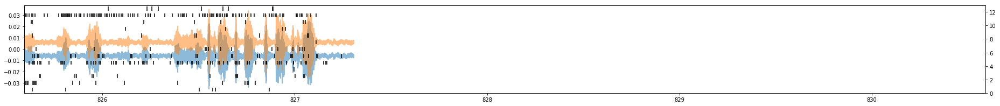

student_song_1
1


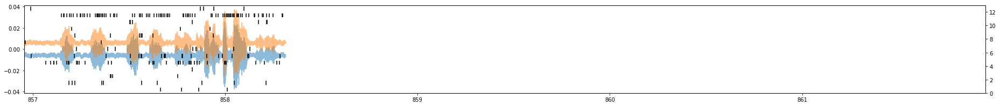

student_song_2
2


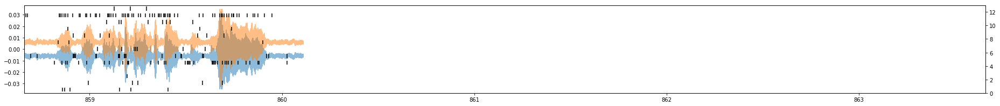

student_song_3
3


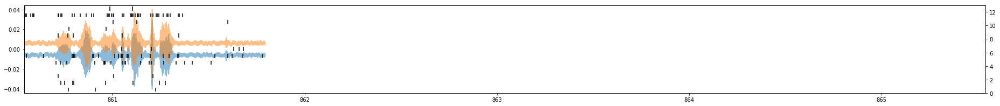

student_song_4
4


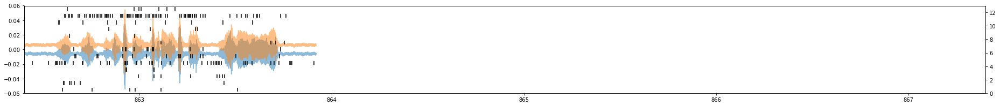

student_song_5
5


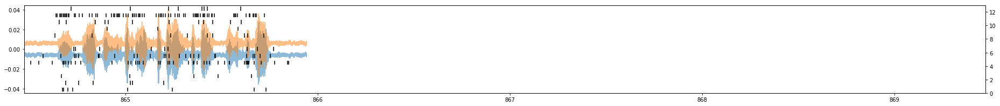

student_song_6
6


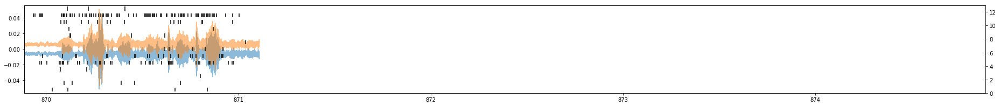

student_song_7
7


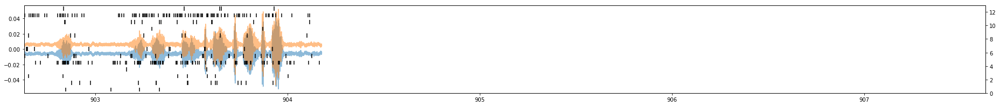

student_song_8
8


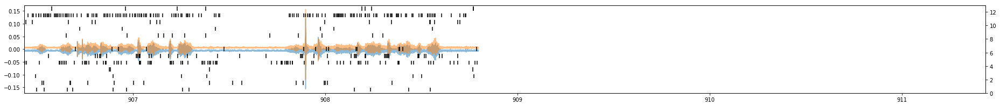

student_song_9
9


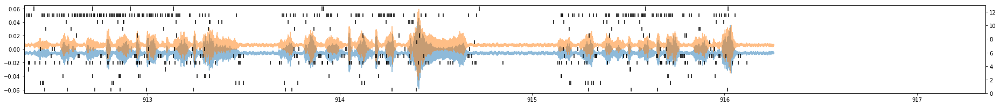

student_song_10
10


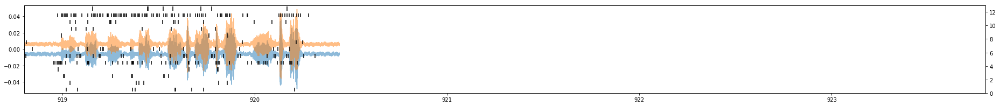

student_song_11
11


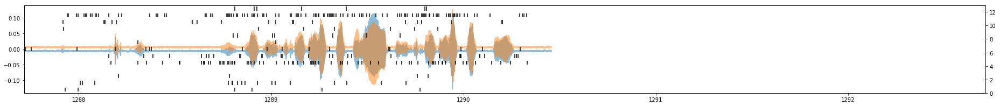

student_song_12
12


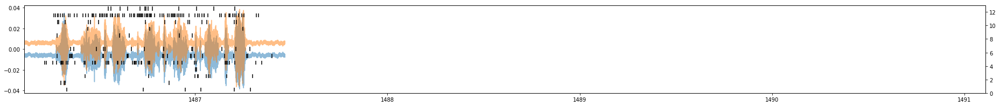

student_song_13
13


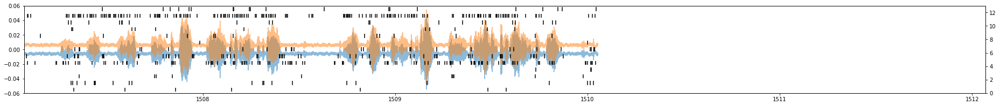

student_song_14
14


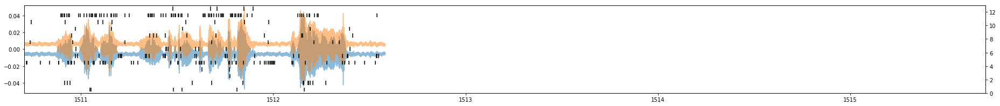

student_song_15
15


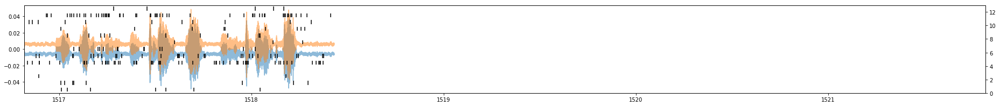

student_song_16
16


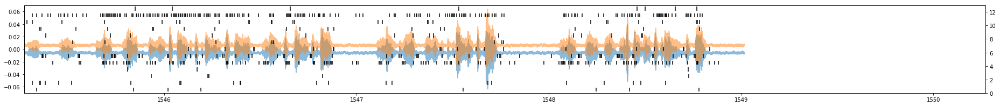

student_song_17
17


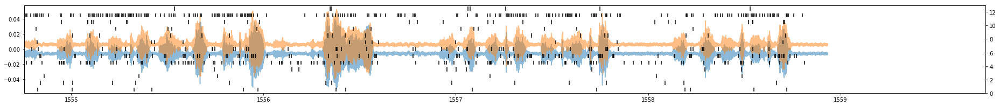

student_song_18
18


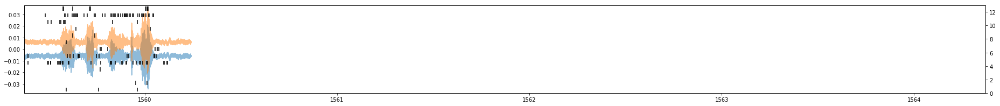

student_song_19
19


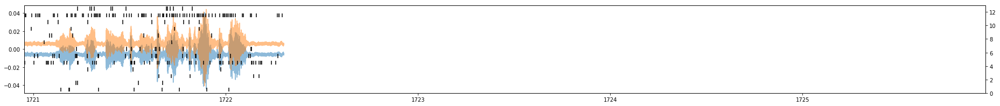

student_song_20
20


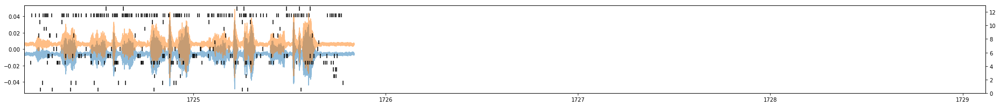

student_song_21
21


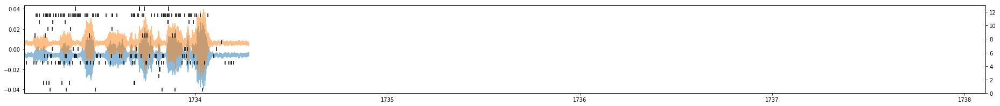

student_song_22
22


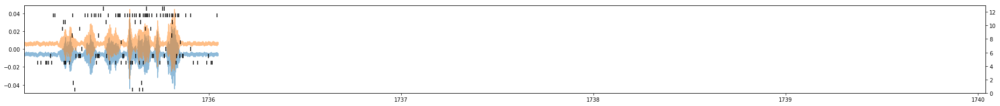

student_song_23
23


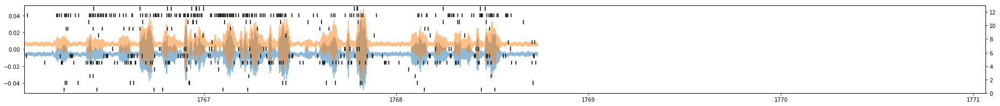

student_song_24
24


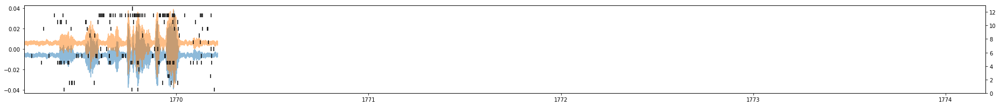

student_song_25
25


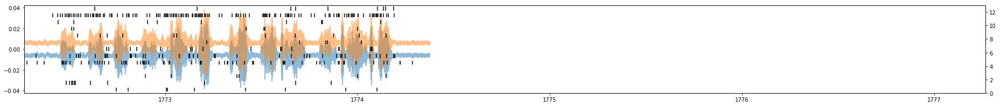

student_song_26
26


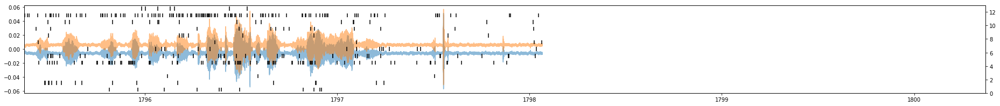

student_song_27
27


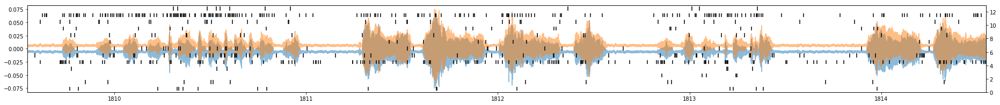

student_song_28
28


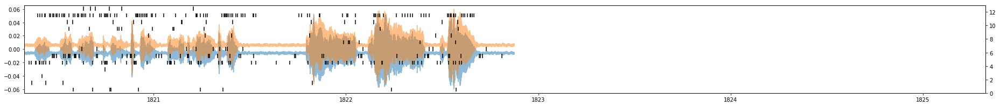

student_song_29
29


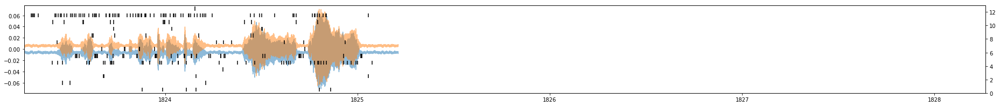

student_song_30
30


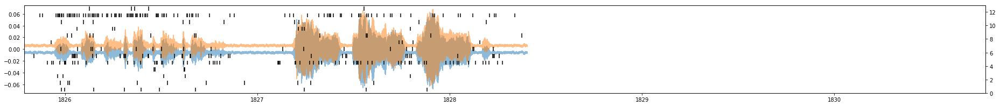

student_song_31
31


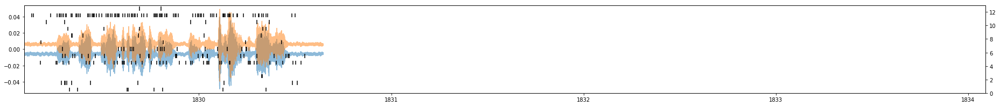

student_song_32
32


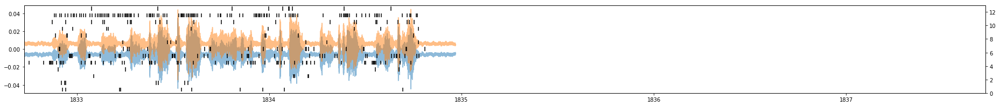

student_song_33
33


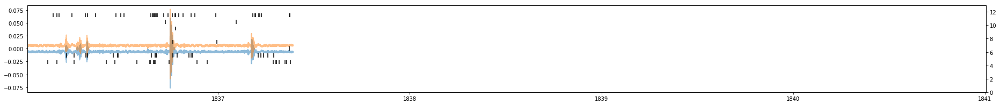

student_song_34
34


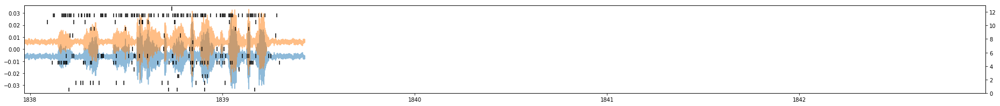

student_song_35
35


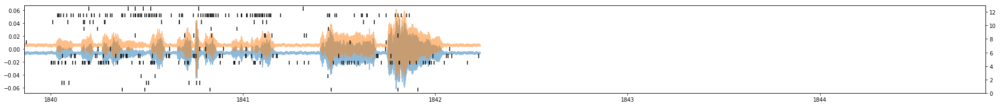

student_song_36
36


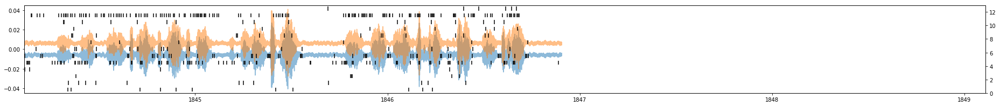

student_song_37
37


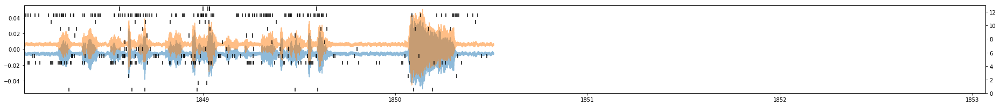

student_song_38
38


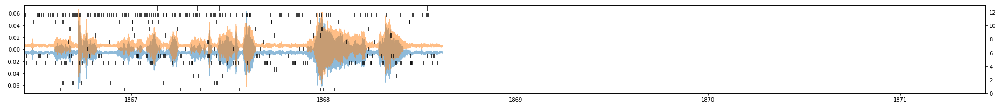

student_song_39
39


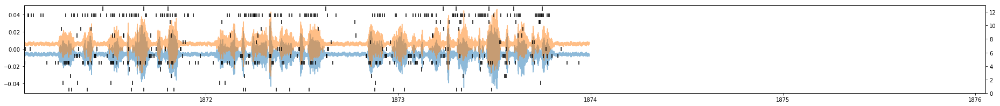

student_song_40
40


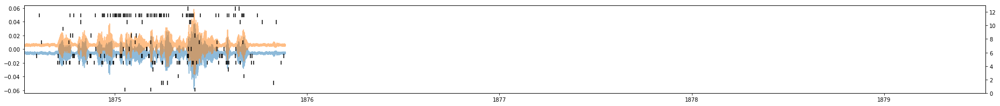

student_song_41
41


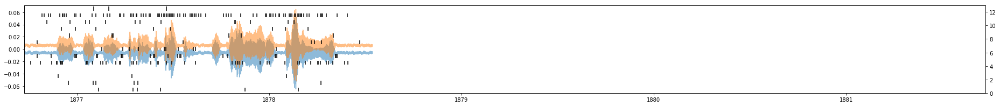

student_song_42
42


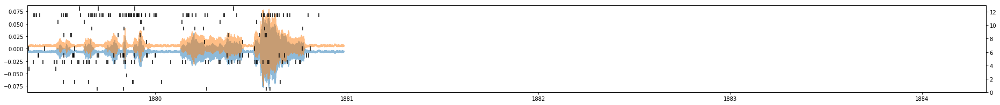

student_song_43
43


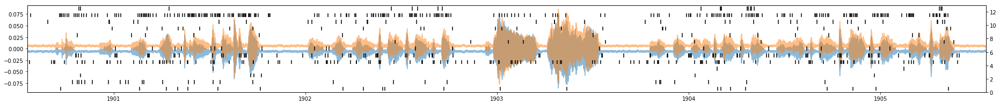

student_song_44
44


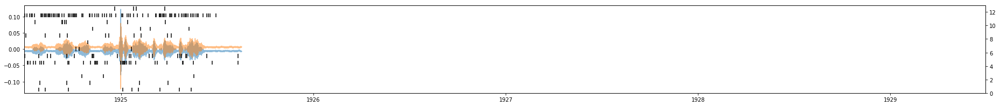

student_song_45
45


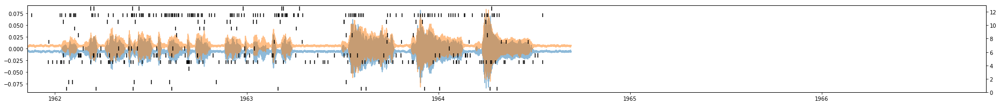

student_song_46
46


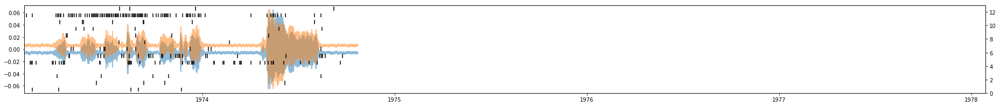

student_song_47
47


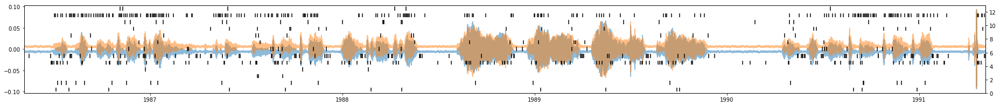

student_song_48
48


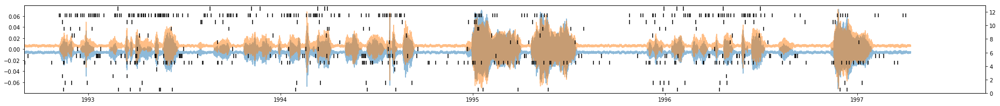

student_song_49
49


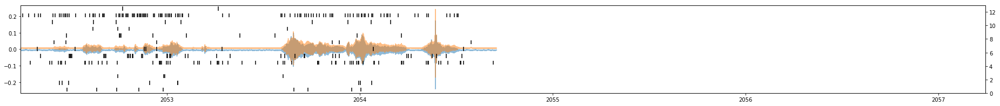

student_song_50
50


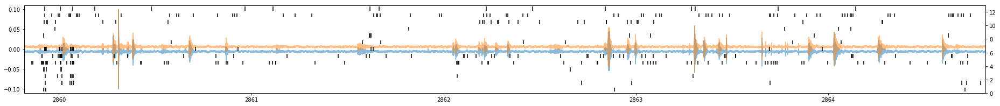

student_song_51
51


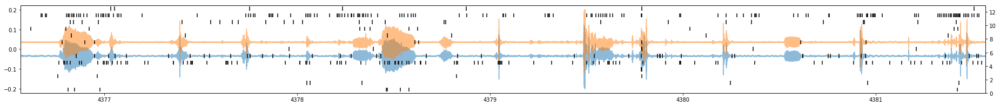

student_song_52
52


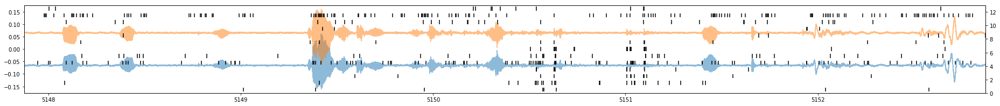

tutor_song_0
53


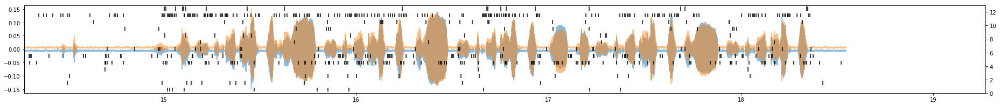

tutor_song_1
54


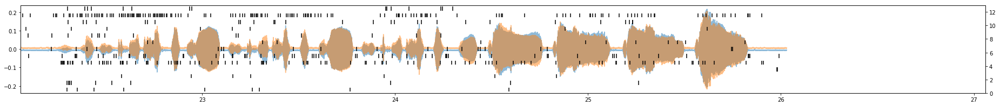

tutor_song_2
55


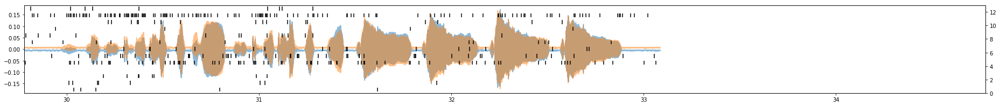

tutor_song_3
56


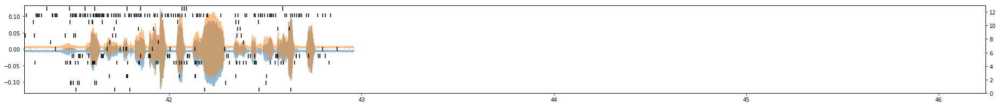

tutor_song_4
57


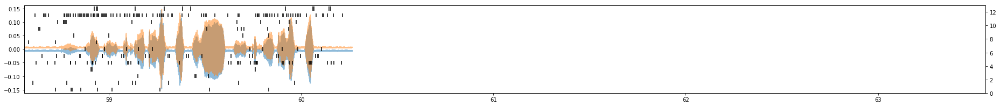

tutor_song_5
58


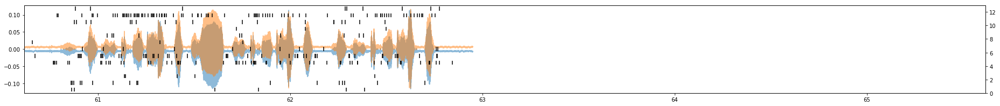

tutor_song_6
59


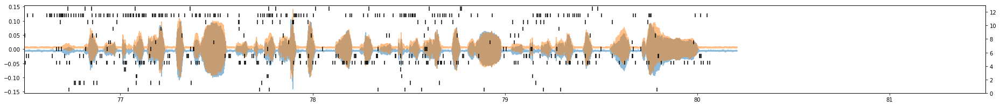

tutor_song_7
60


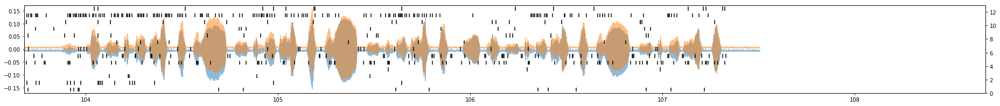

tutor_song_8
61


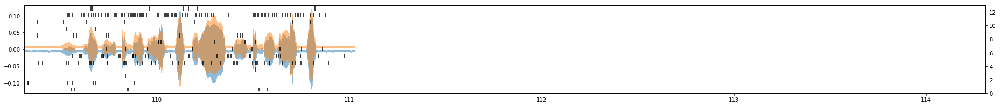

tutor_song_9
62


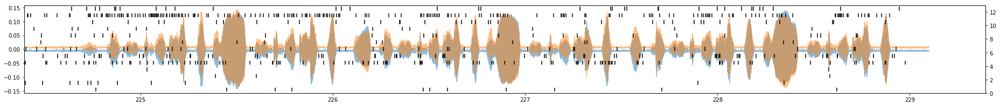

tutor_song_10
63


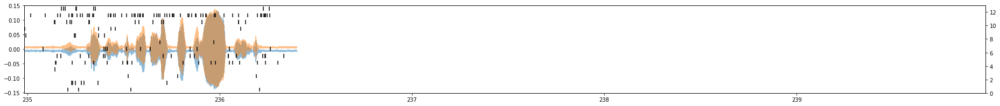

tutor_song_11
64


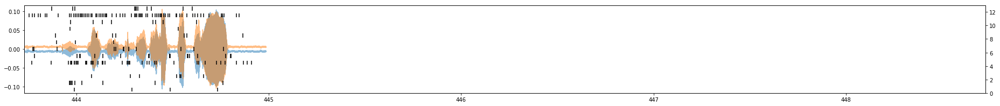

tutor_song_12
65


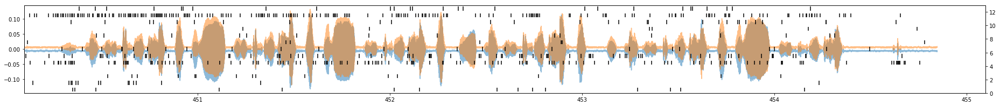

tutor_song_13
66


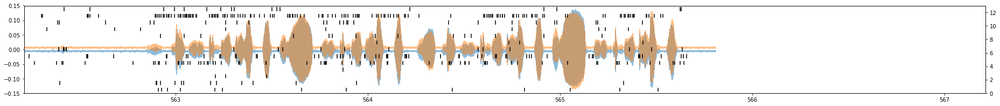

tutor_song_14
67


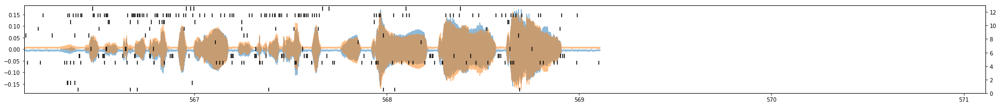

tutor_song_15
68


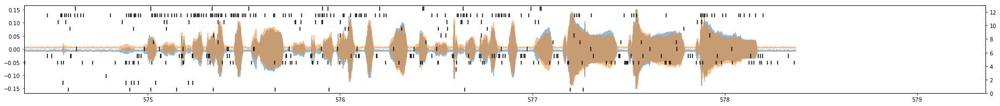

tutor_song_16
69


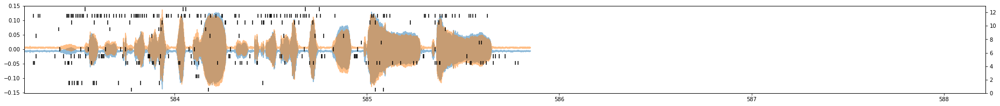

tutor_song_17
70


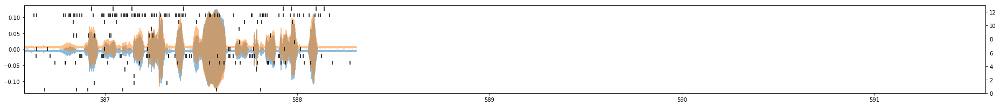

tutor_song_18
71


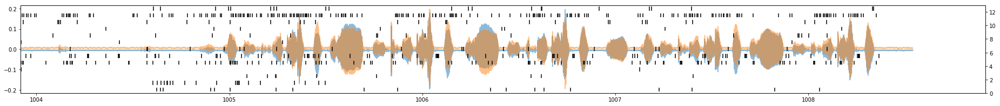

tutor_song_19
72


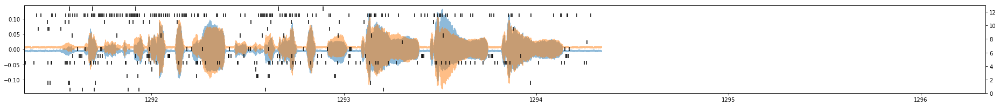

tutor_song_20
73


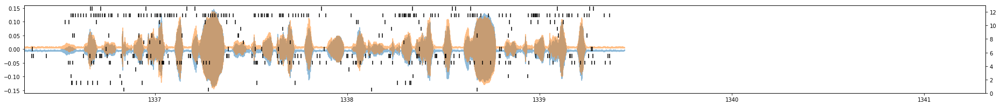

tutor_song_21
74


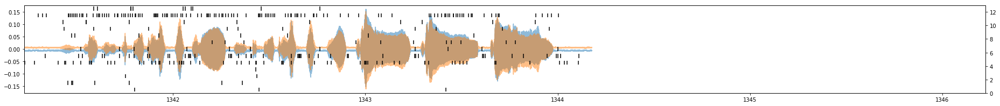

tutor_song_22
75


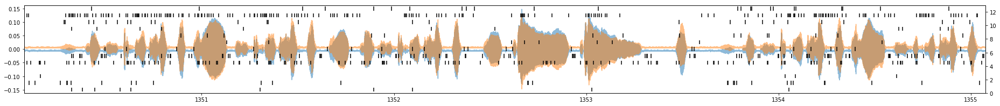

tutor_song_23
76


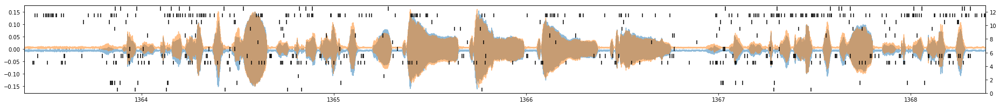

tutor_song_24
77


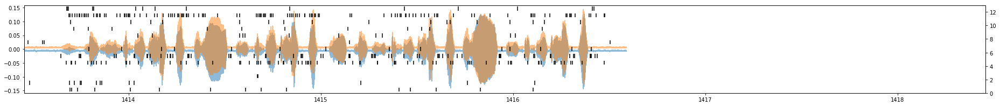

tutor_song_25
78


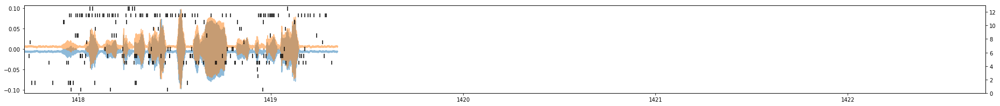

tutor_song_26
79


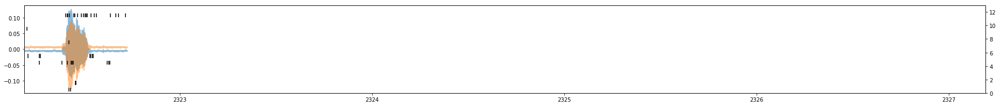

tutor_song_27
80


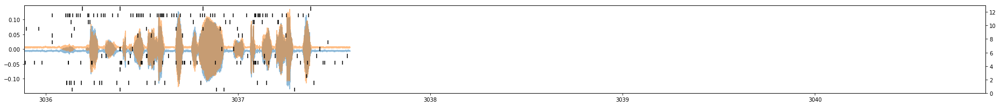

tutor_song_28
81


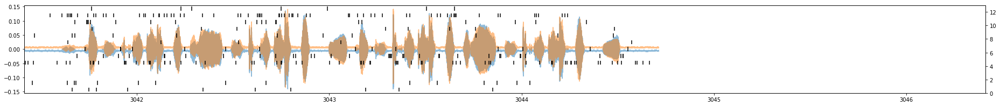

tutor_song_29
82


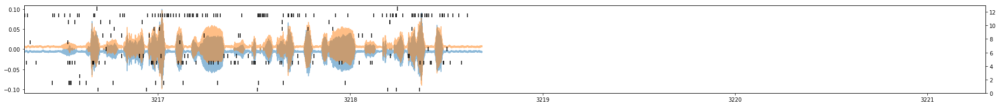

tutor_song_30
83


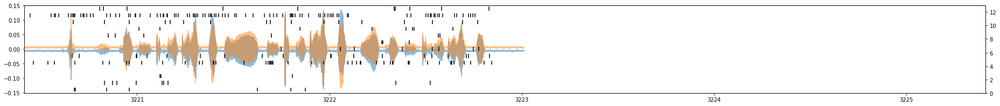

tutor_song_31
84


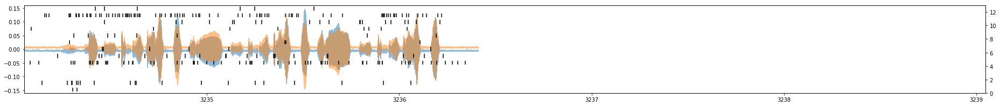

tutor_song_32
85


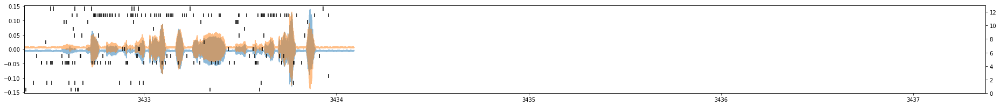

tutor_song_33
86


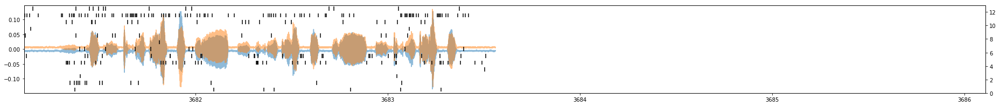

tutor_song_34
87


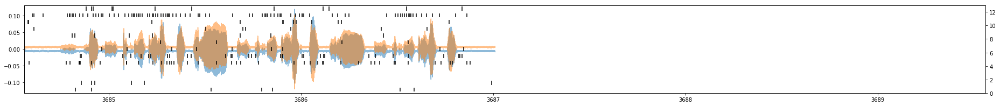

tutor_song_35
88


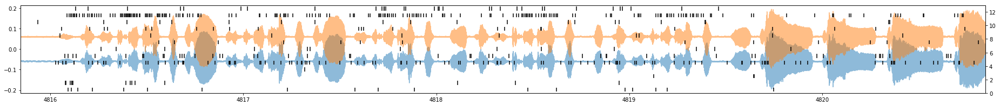

tutor_song_36
89


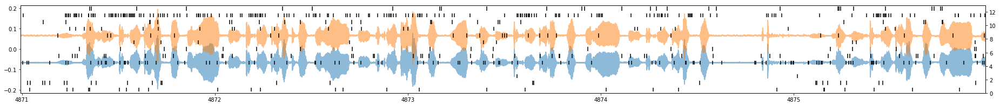

tutor_song_37
90


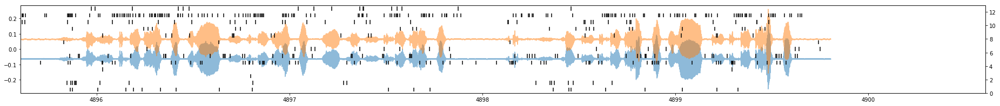

tutor_song_38
91


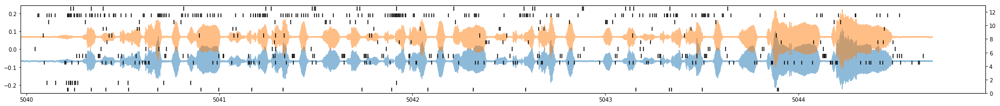

tutor_song_39
92


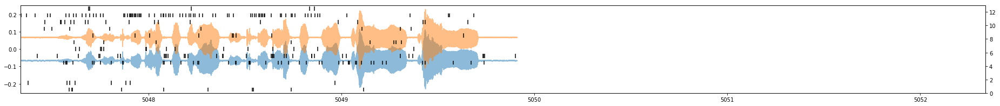

tutor_song_40
93


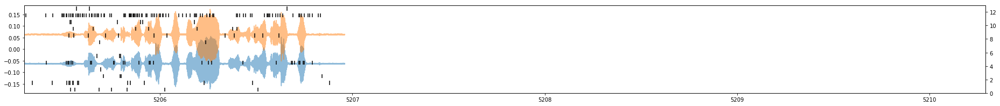

tutor_song_41
94


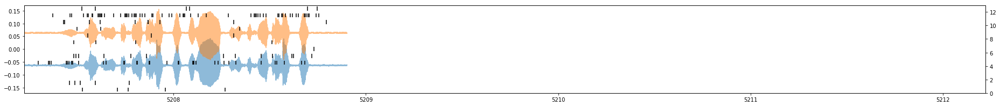

tutor_song_42
95


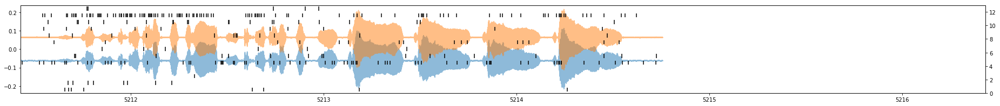

tutor_song_43
96


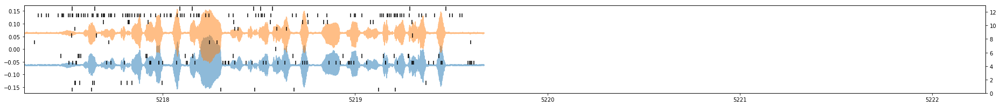

tutor_song_44
97


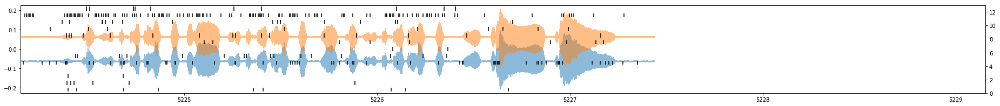

tutor_song_45
98


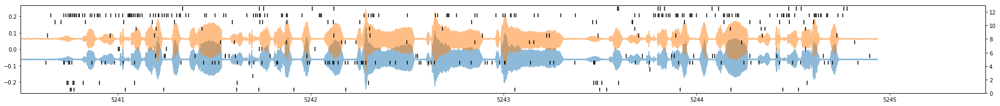

tutor_song_46
99


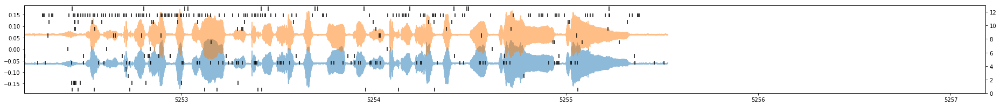

tutor_song_47
100


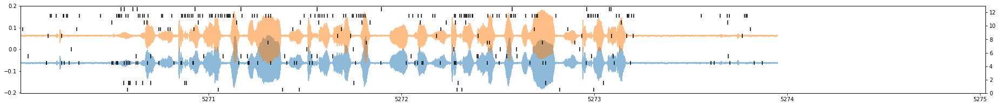

tutor_song_48
101


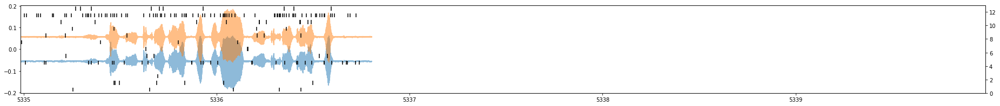

In [22]:
for seg_idx in range(len(block.segments)):
    
    seg = block.segments[seg_idx]
    
    print seg.name
    print seg_idx
    
    # here we need to figure out which units look reasonable
    
    spiketrains = [st for st in seg.spiketrains]

    sound = seg.analogsignals[0].as_array()[:, 0]
    sound1 = seg.analogsignals[0].as_array()[:, 1]
    fig, ax = plt.subplots(figsize=(32, 3))

    plot_spikes_with_timeseries(
        np.linspace(seg.t_start.item(), seg.t_stop.item(), len(sound)),
        spiketrains,
        seg.analogsignals[0].T - np.mean(seg.analogsignals[0].T, axis=0),
        seg.t_start.item(),
        seg.t_start.item() + 5.0,
        ax=ax,
        spike_alpha=1.0,
        y_alpha=[0.5, 0.5]
    )

    plt.show()

In [30]:
BIRD2 = "LbY6074__161215_132633"
data_path2 = os.path.join(DATADIR, "birds", "LbY6074", "RHD", "{}-sorted.pkl".format(BIRD2))
# ../../data/birds/LbY6074/RHD/LbY6074__161215_145633.

In [31]:
with open(data_path2, "rb") as datafile:
    block2 = pickle.load(datafile)
block2.create_relationship(recursive=True, force=True, append=True)

In [32]:
block2.channel_indexes

[ChannelIndex with  name: 'Amp Elec 0',
 ChannelIndex with  name: 'Amp Elec 1',
 ChannelIndex with  name: 'Amp Elec 2',
 ChannelIndex with 1 units name: 'Amp Elec 3',
 ChannelIndex with 2 units name: 'Amp Elec 4',
 ChannelIndex with 4 units name: 'Amp Elec 5',
 ChannelIndex with 3 units name: 'Amp Elec 6',
 ChannelIndex with  name: 'Amp Elec 7',
 ChannelIndex with 1 units name: 'Amp Elec 8',
 ChannelIndex with 2 units name: 'Amp Elec 9',
 ChannelIndex with 3 units name: 'Amp Elec 10',
 ChannelIndex with 1 units name: 'Amp Elec 11',
 ChannelIndex with  name: 'Amp Elec 12',
 ChannelIndex with 2 units name: 'Amp Elec 13',
 ChannelIndex with  name: 'Amp Elec 14',
 ChannelIndex with  name: 'Amp Elec 15',
 ChannelIndex with 417 analogsignals name: 'ADC']

student_song_0
0


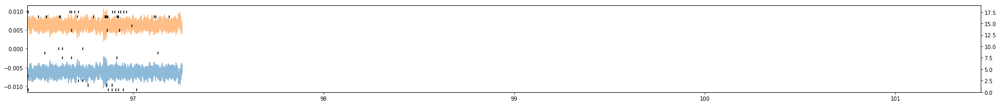

student_song_1
1


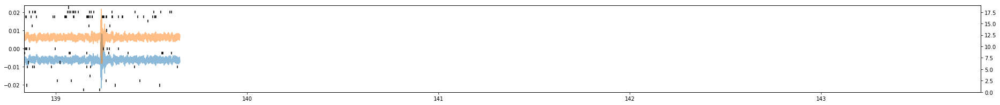

student_song_2
2


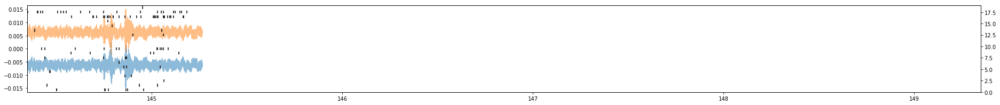

student_song_3
3


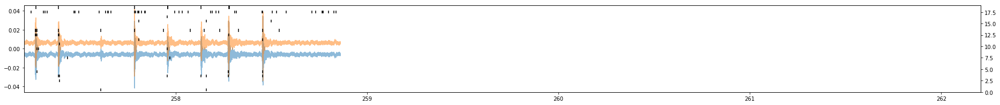

student_song_4
4


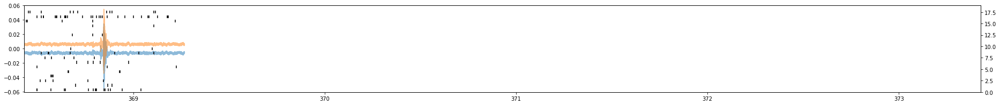

student_song_5
5


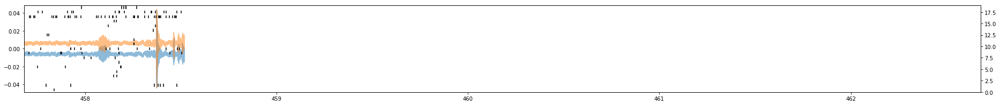

student_song_6
6


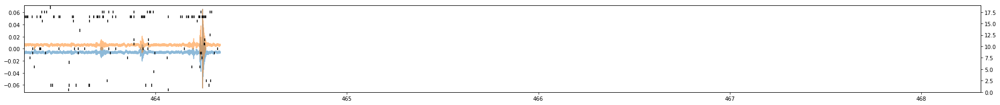

student_song_7
7


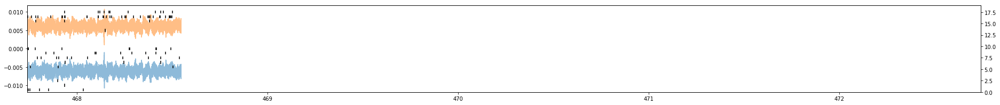

student_song_8
8


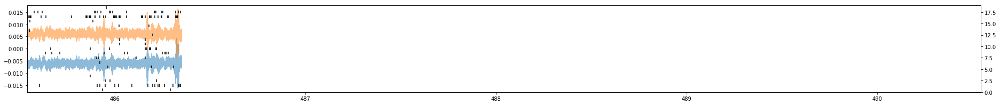

student_song_9
9


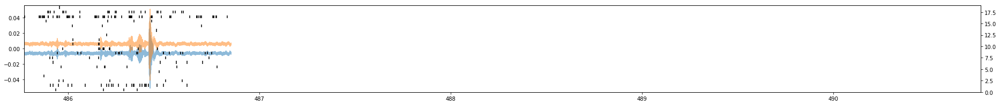

student_song_10
10


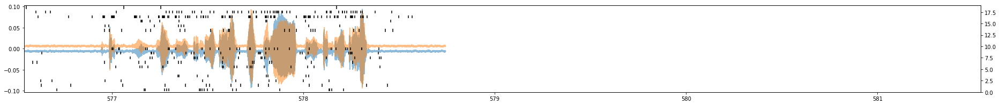

student_song_11
11


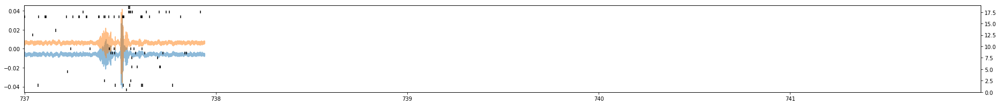

student_song_12
12


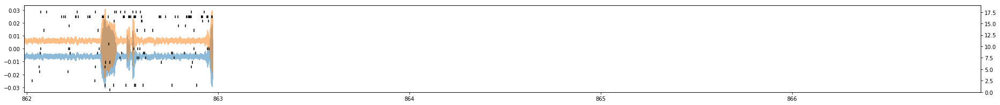

student_song_13
13


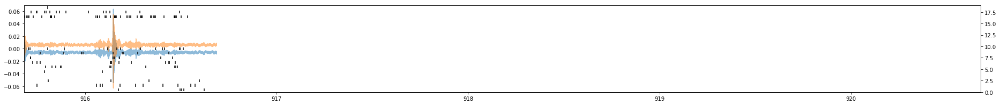

student_song_14
14


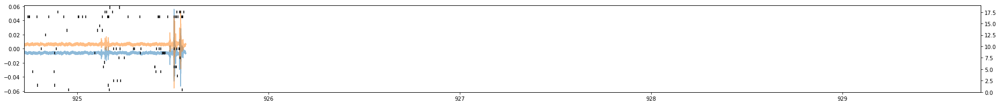

student_song_15
15


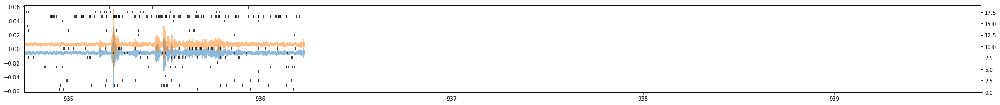

student_song_16
16


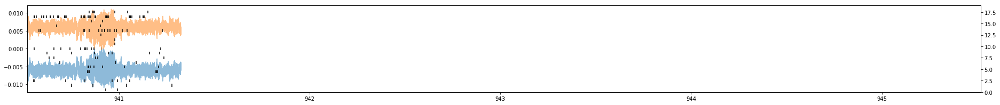

student_song_17
17


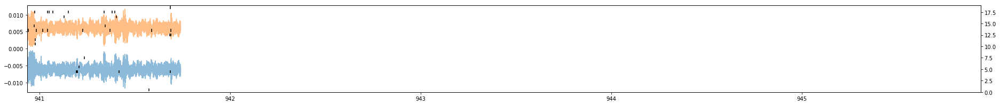

student_song_18
18


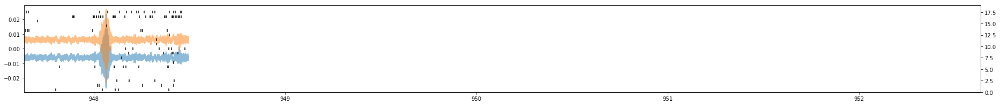

student_song_19
19


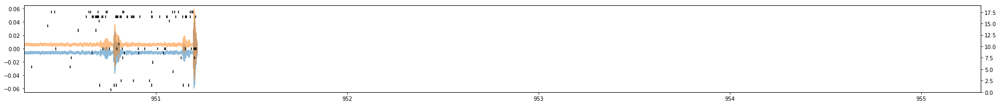

student_song_20
20


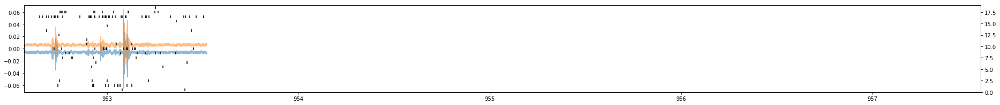

student_song_21
21


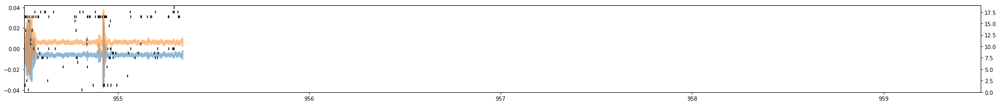

student_song_22
22


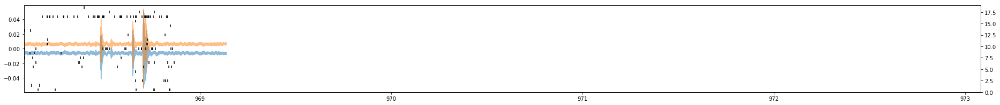

student_song_23
23


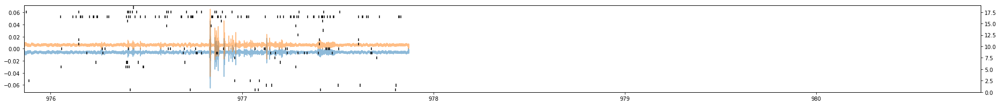

student_song_24
24


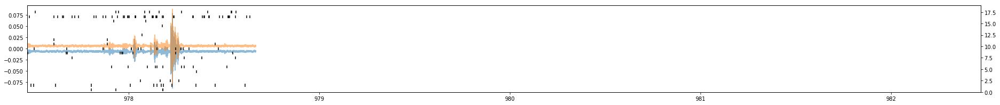

student_song_25
25


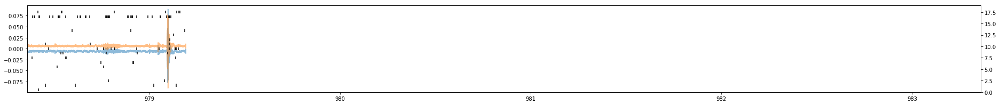

student_song_26
26


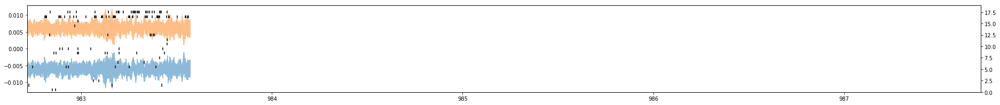

student_song_27
27


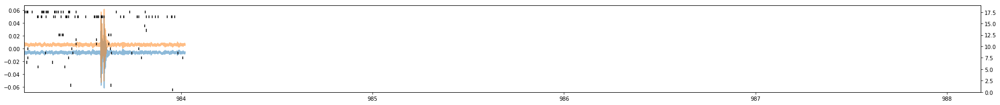

student_song_28
28


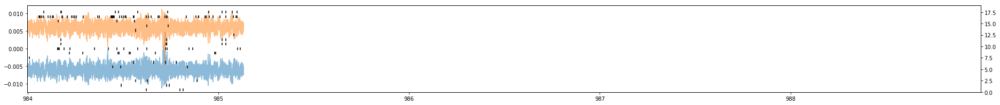

student_song_29
29


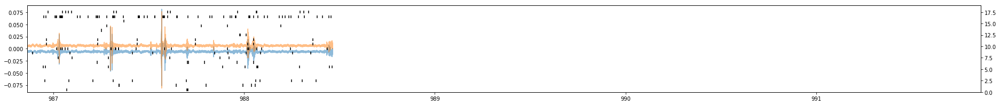

student_song_30
30


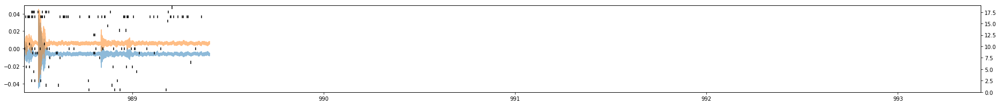

student_song_31
31


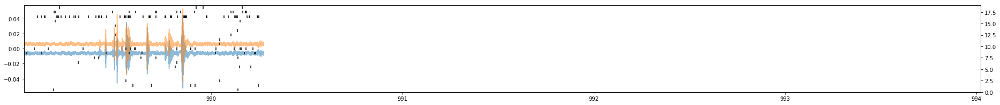

student_song_32
32


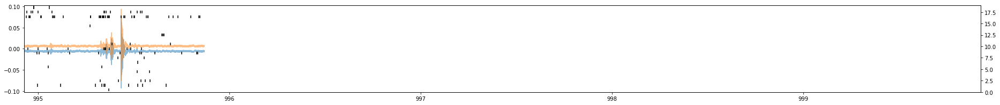

student_song_33
33


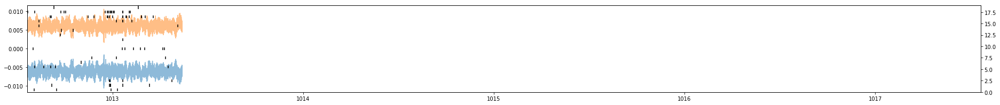

student_song_34
34


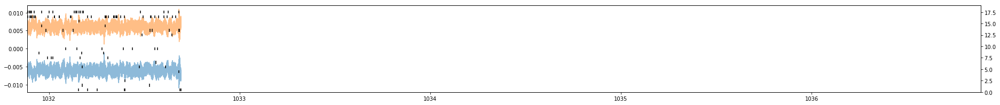

student_song_35
35


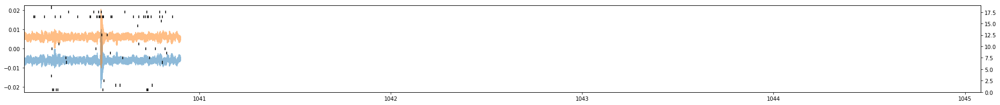

student_song_36
36


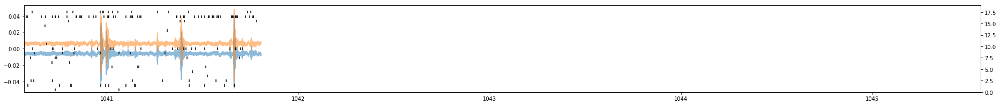

student_song_37
37


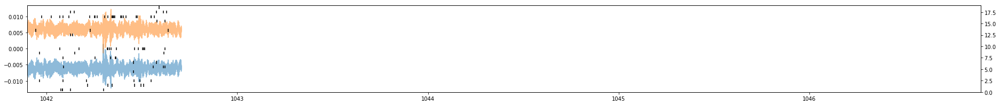

student_song_38
38


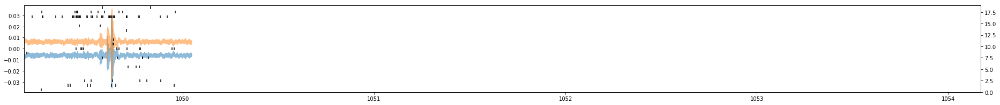

student_song_39
39


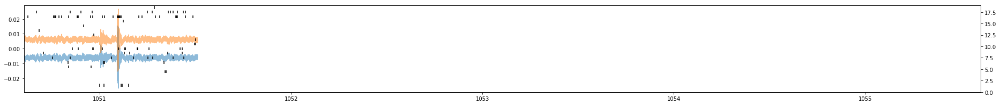

student_song_40
40


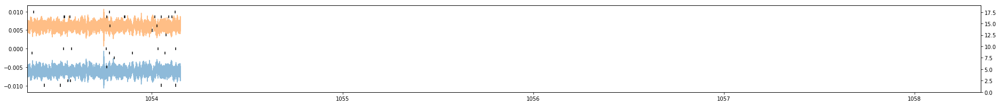

student_song_41
41


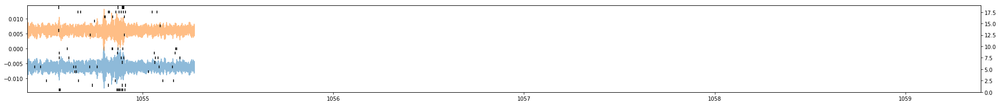

student_song_42
42


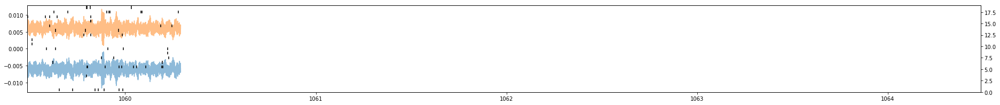

student_song_43
43


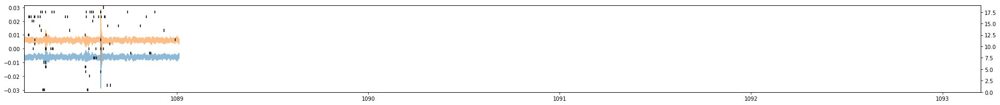

student_song_44
44


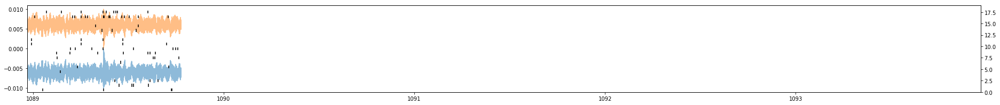

student_song_45
45


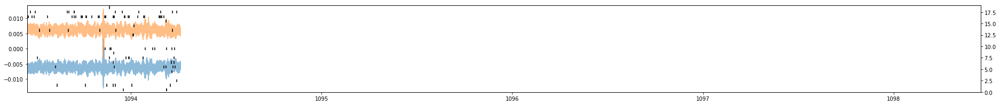

student_song_46
46


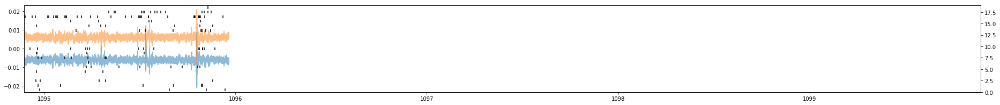

student_song_47
47


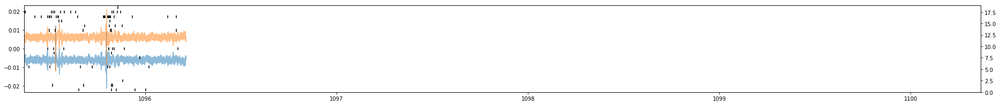

student_song_48
48


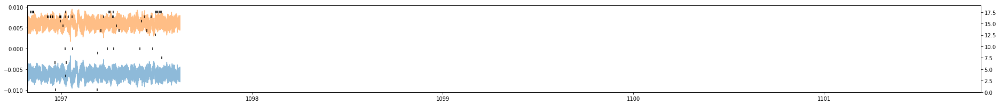

student_song_49
49


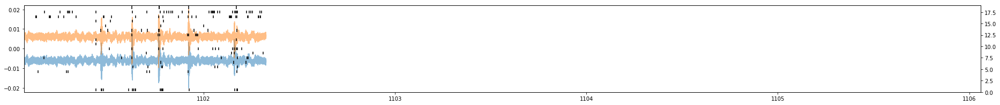

student_song_50
50


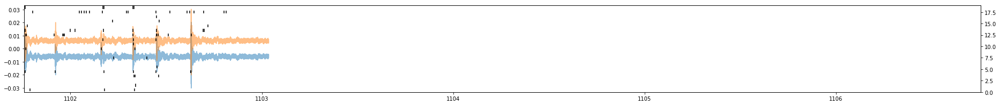

student_song_51
51


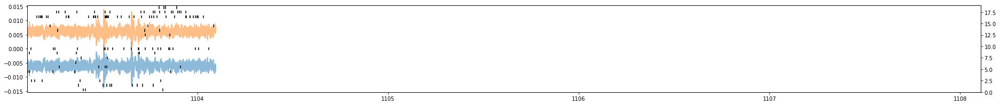

student_song_52
52


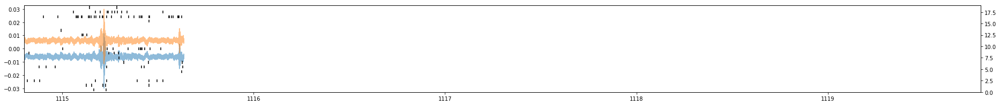

student_song_53
53


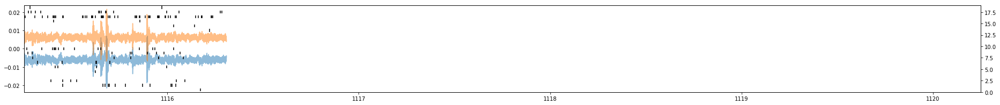

student_song_54
54


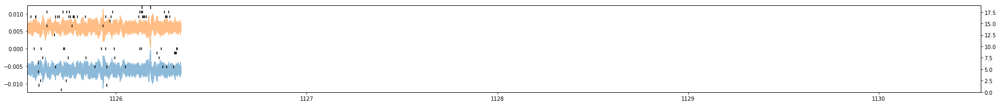

student_song_55
55


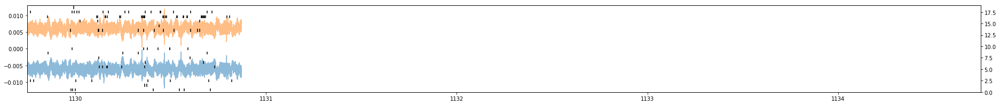

student_song_56
56


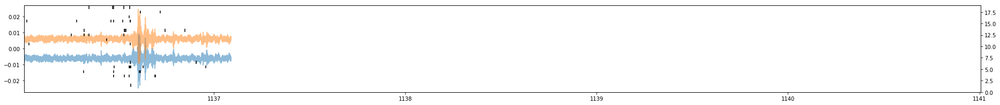

student_song_57
57


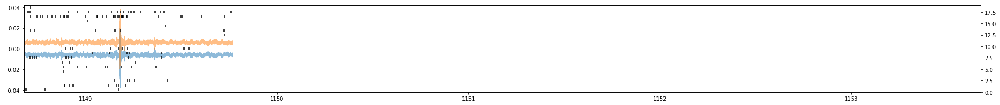

student_song_58
58


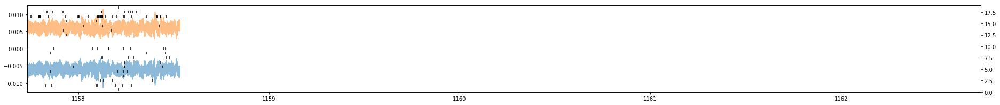

student_song_59
59


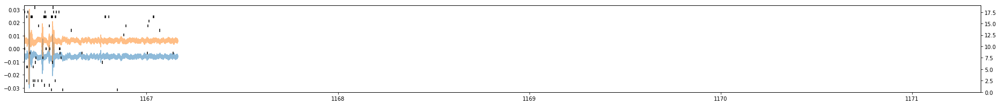

student_song_60
60


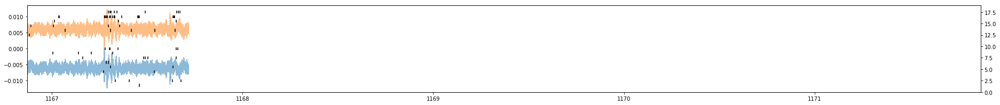

student_song_61
61


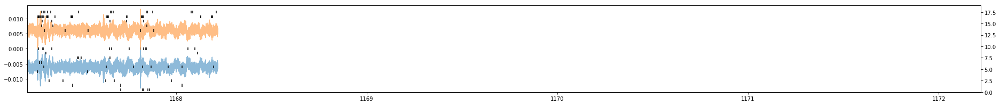

student_song_62
62


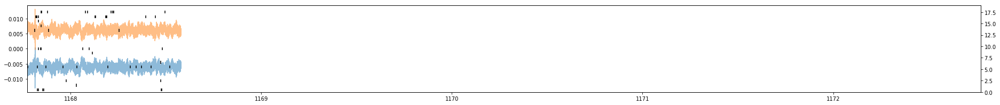

student_song_63
63


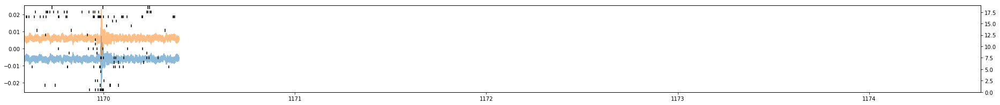

student_song_64
64


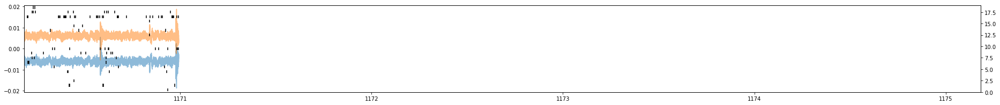

student_song_65
65


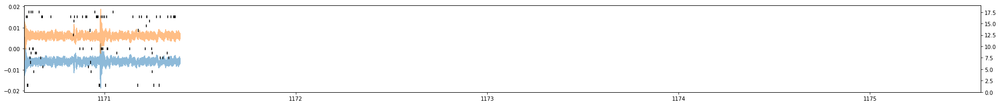

student_song_66
66


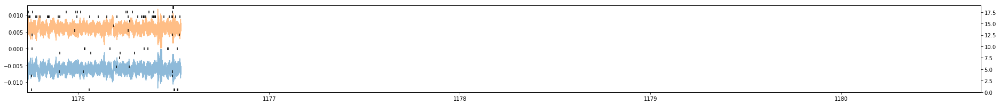

student_song_67
67


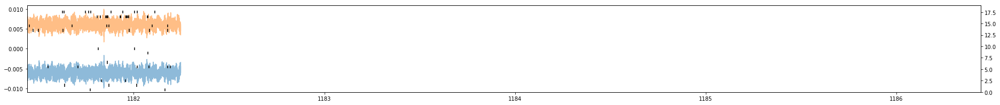

student_song_68
68


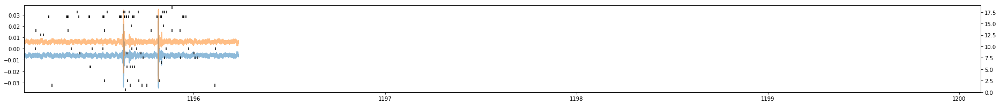

student_song_69
69


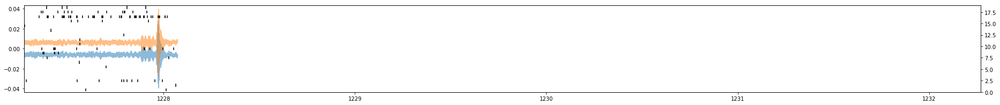

student_song_70
70


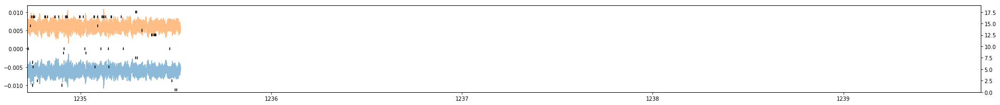

student_song_71
71


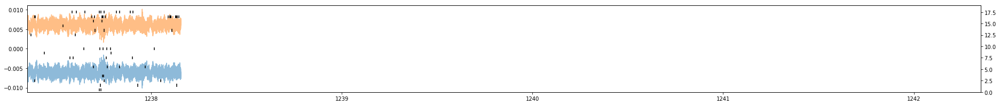

student_song_72
72


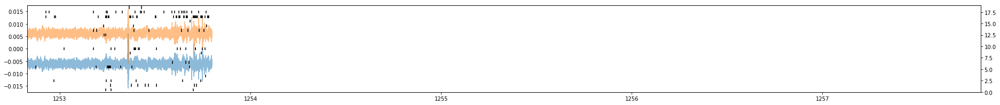

student_song_73
73


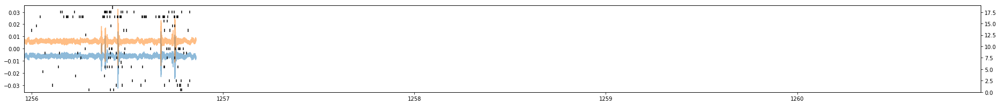

student_song_74
74


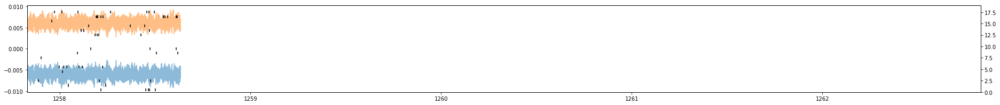

student_song_75
75


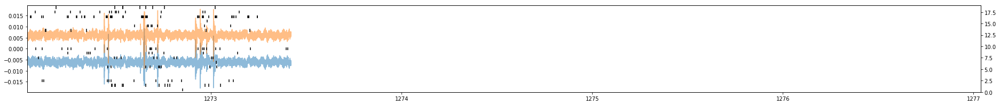

student_song_76
76


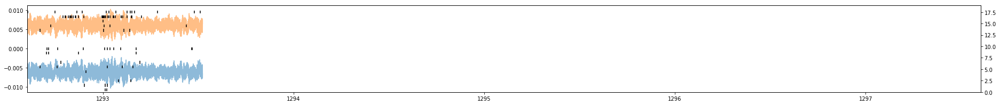

student_song_77
77


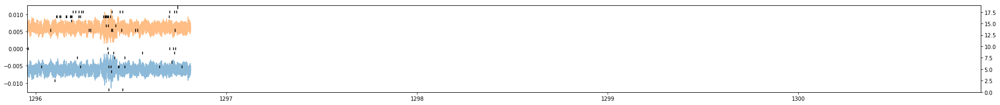

student_song_78
78


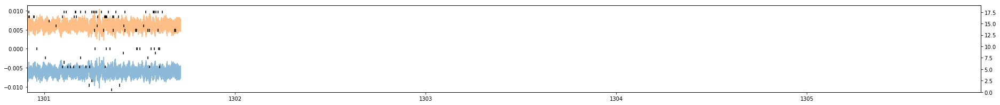

student_song_79
79


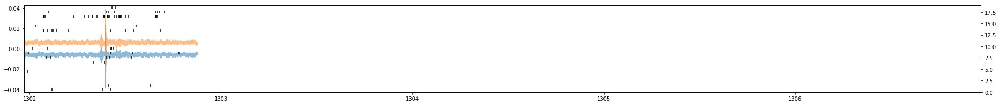

student_song_80
80


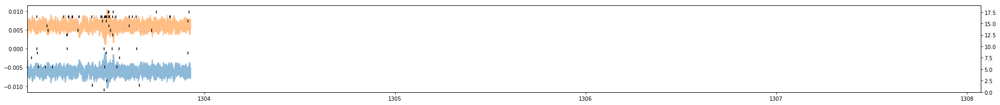

student_song_81
81


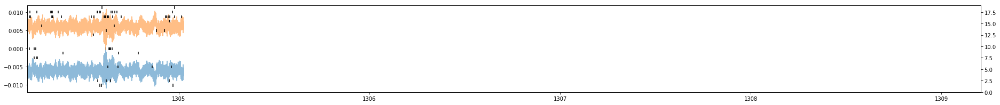

student_song_82
82


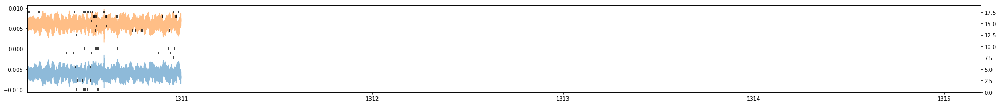

student_song_83
83


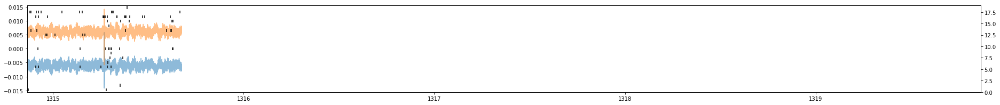

student_song_84
84


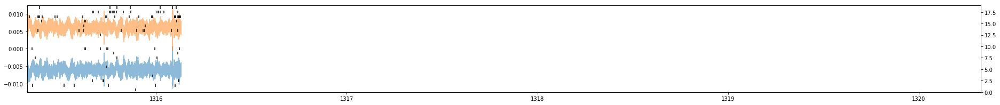

student_song_85
85


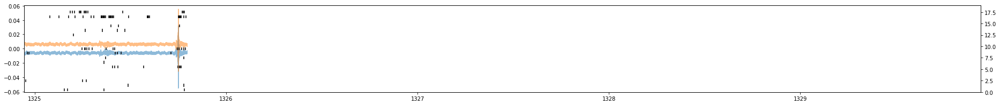

student_song_86
86


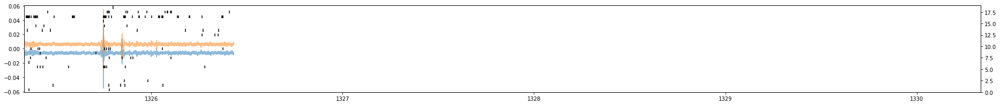

student_song_87
87


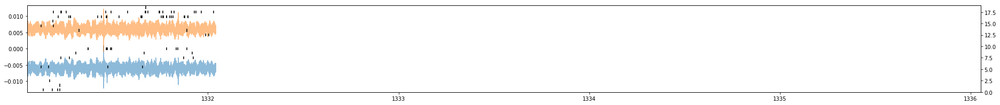

student_song_88
88


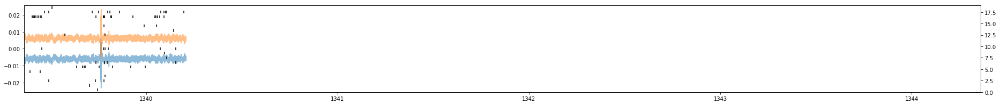

student_song_89
89


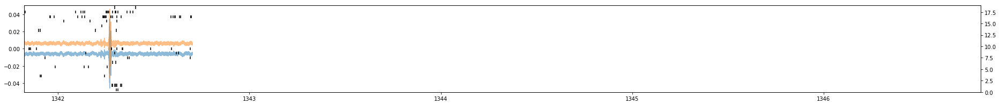

student_song_90
90


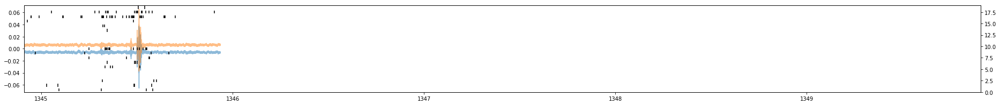

student_song_91
91


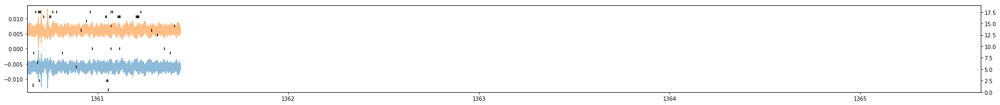

student_song_92
92


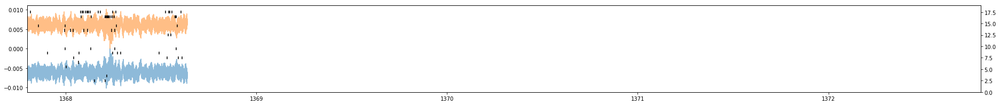

student_song_93
93


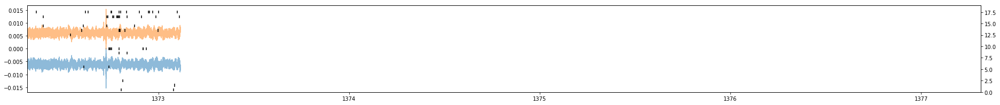

student_song_94
94


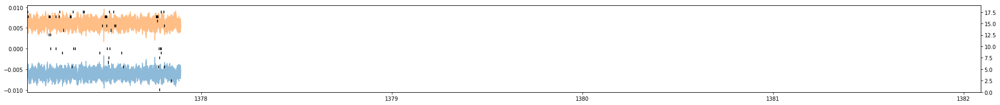

student_song_95
95


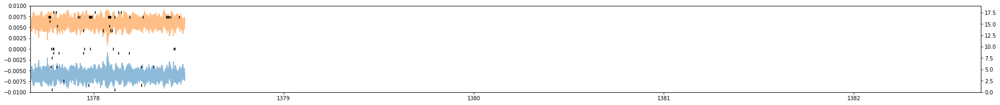

student_song_96
96


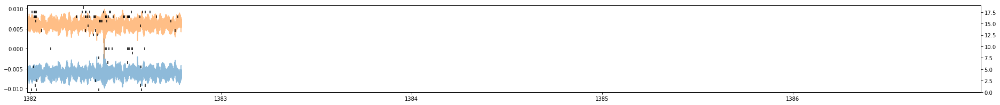

student_song_97
97


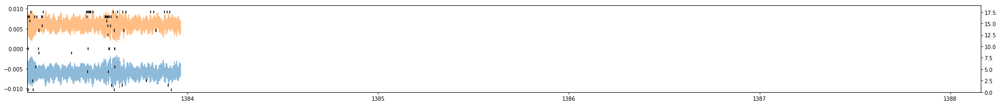

student_song_98
98


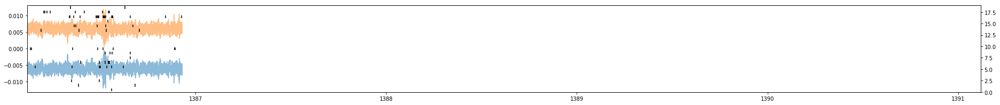

student_song_99
99


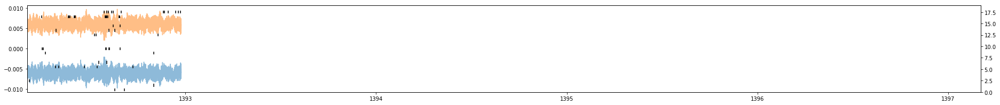

student_song_100
100


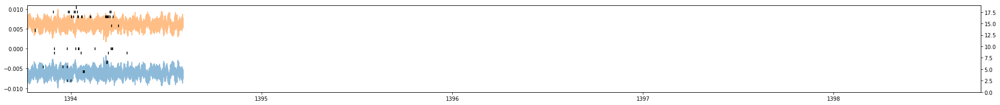

student_song_101
101


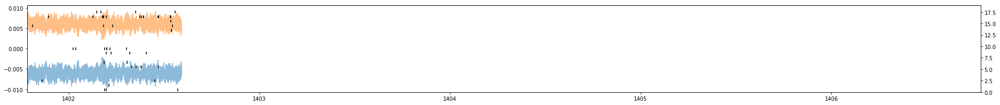

student_song_102
102


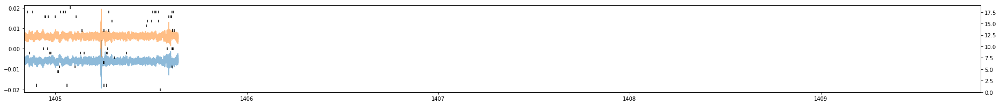

student_song_103
103


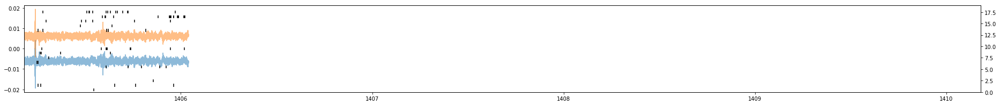

student_song_104
104


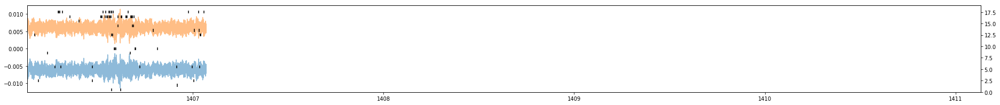

student_song_105
105


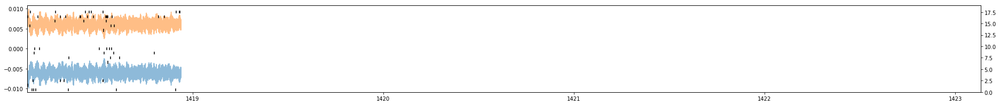

student_song_106
106


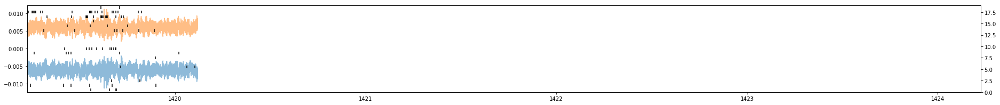

student_song_107
107


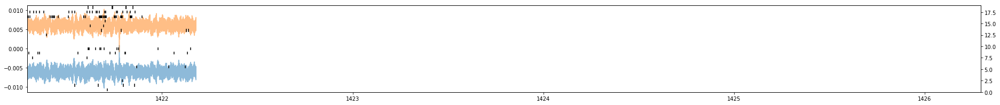

student_song_108
108


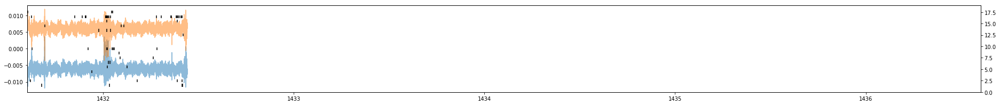

student_song_109
109


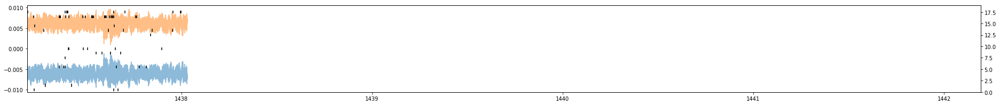

student_song_110
110


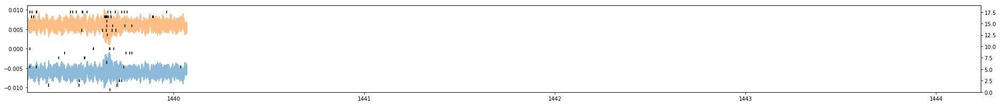

student_song_111
111


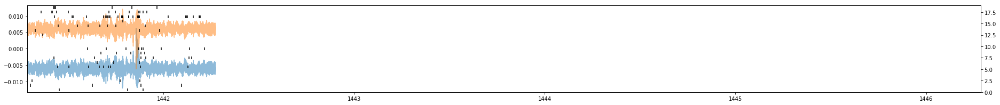

student_song_112
112


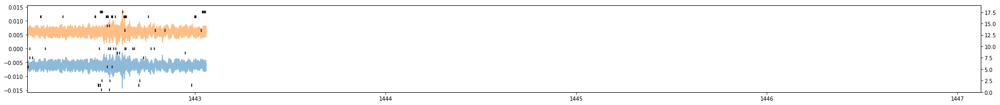

student_song_113
113


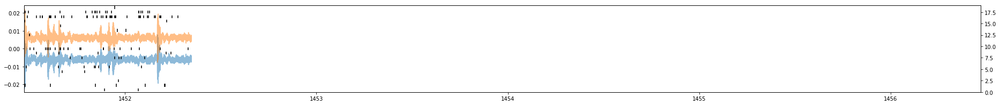

student_song_114
114


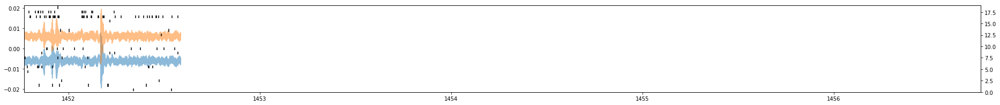

student_song_115
115


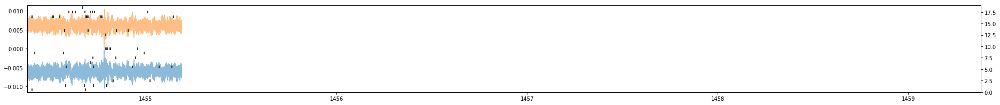

student_song_116
116


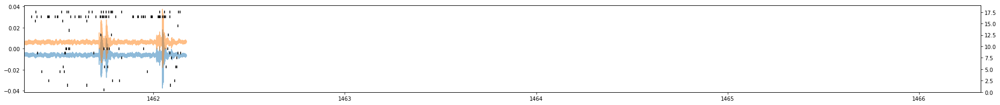

student_song_117
117


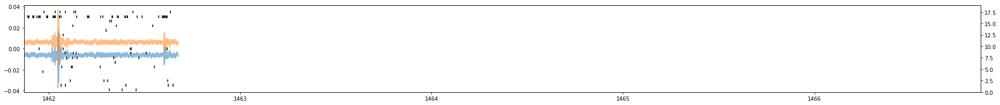

student_song_118
118


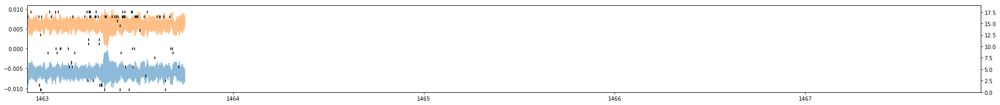

student_song_119
119


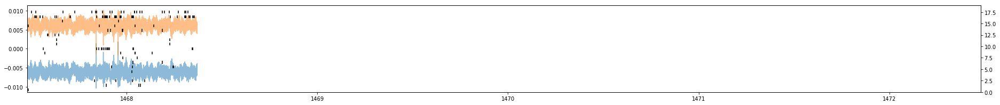

student_song_120
120


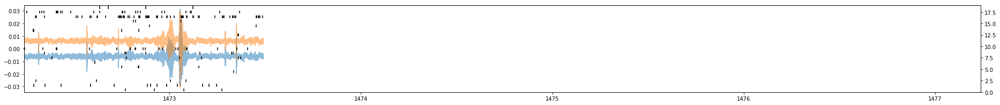

student_song_121
121


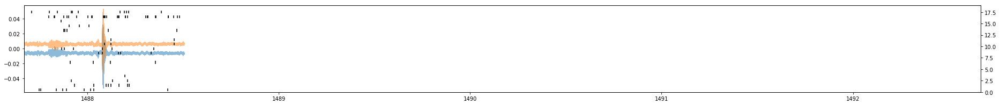

student_song_122
122


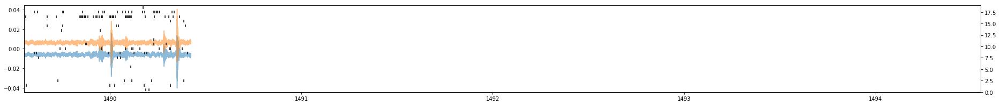

student_song_123
123


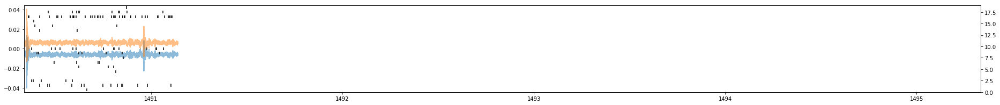

student_song_124
124


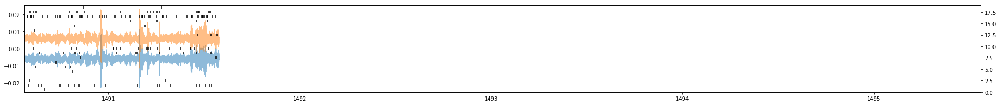

student_song_125
125


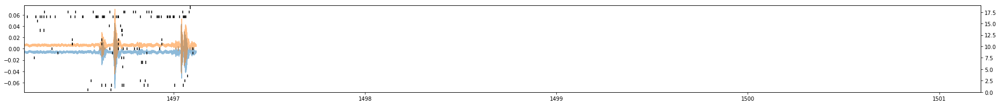

student_song_126
126


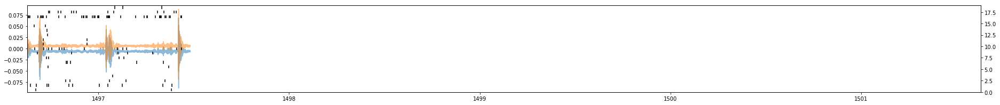

student_song_127
127


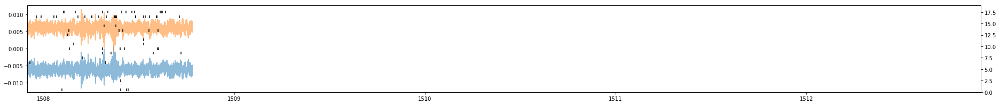

student_song_128
128


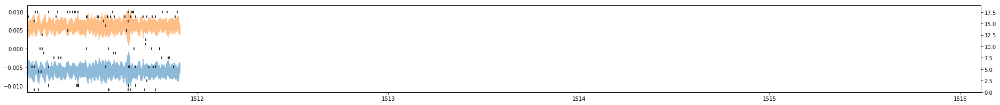

student_song_129
129


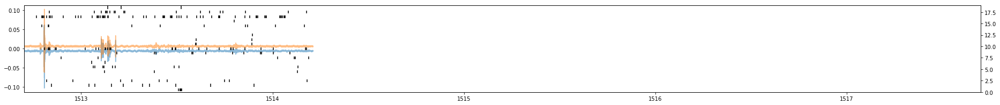

student_song_130
130


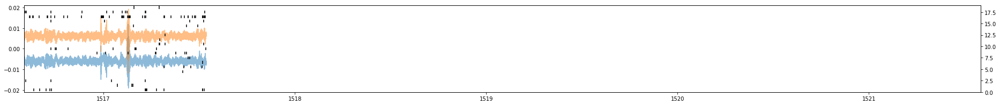

student_song_131
131


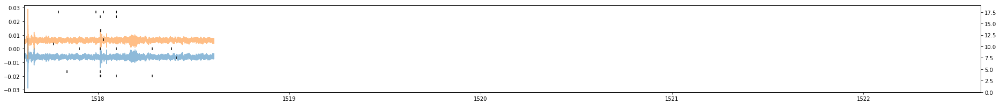

student_song_132
132


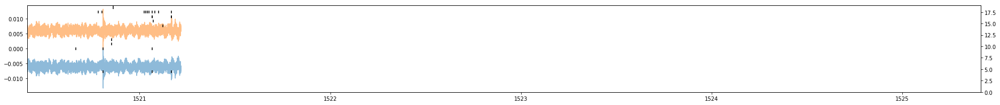

student_song_133
133


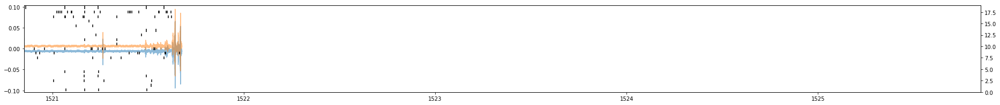

student_song_134
134


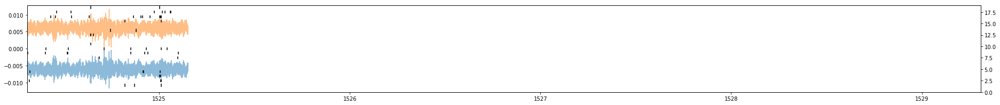

student_song_135
135


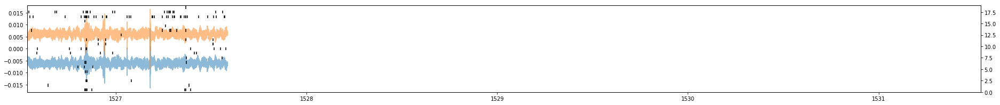

student_song_136
136


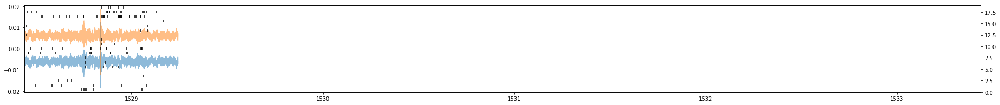

student_song_137
137


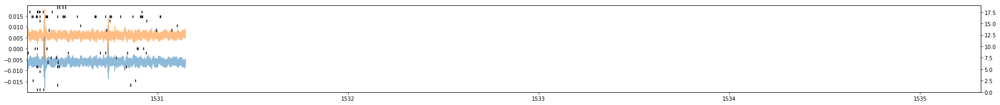

student_song_138
138


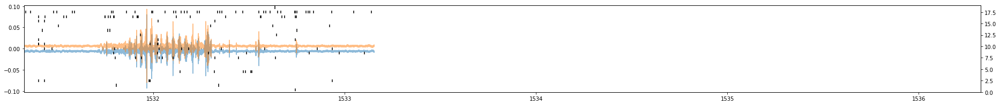

student_song_139
139


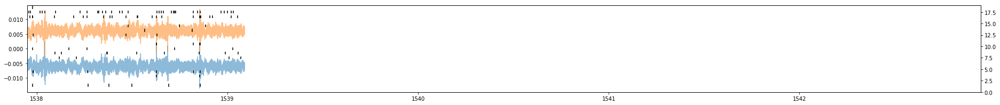

student_song_140
140


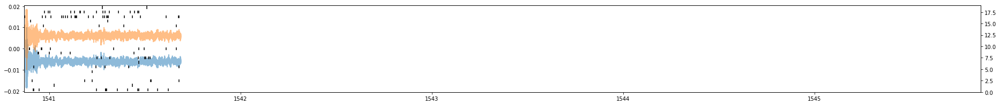

student_song_141
141


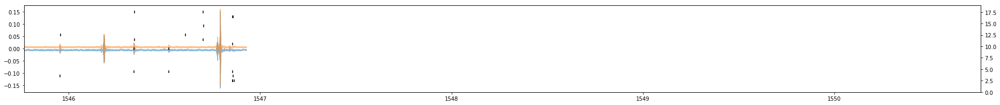

student_song_142
142


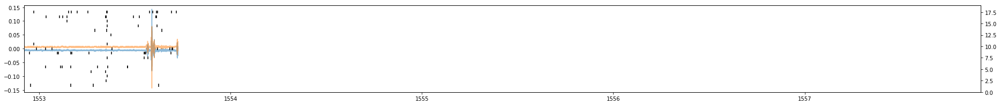

student_song_143
143


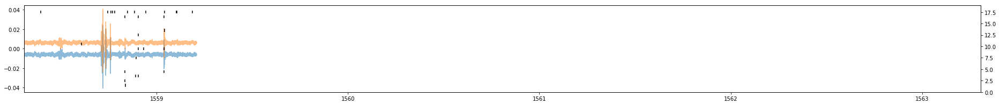

student_song_144
144


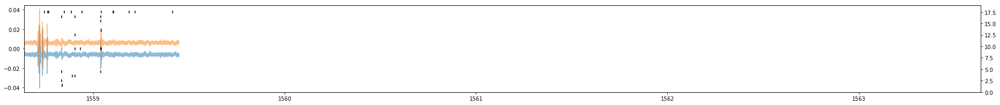

student_song_145
145


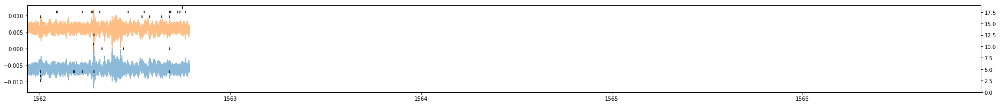

student_song_146
146


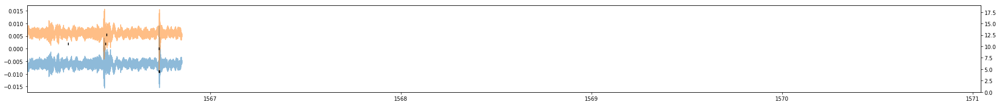

student_song_147
147


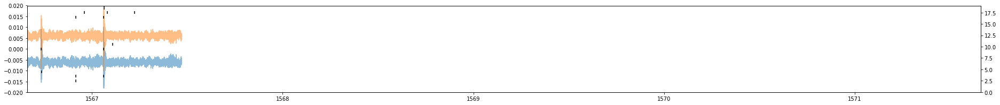

student_song_148
148


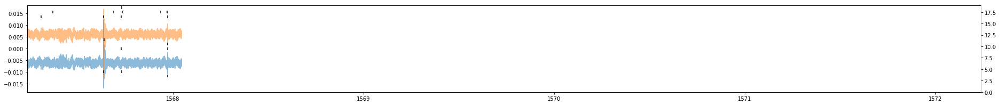

student_song_149
149


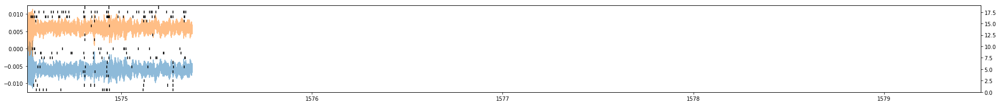

student_song_150
150


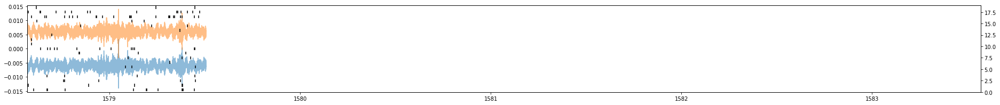

student_song_151
151


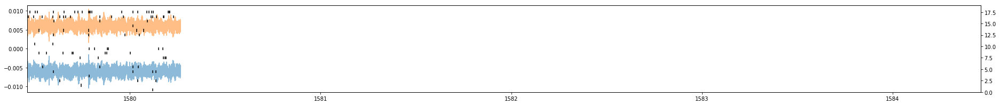

student_song_152
152


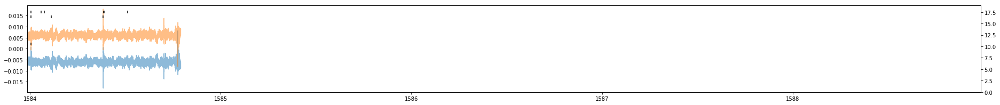

student_song_153
153


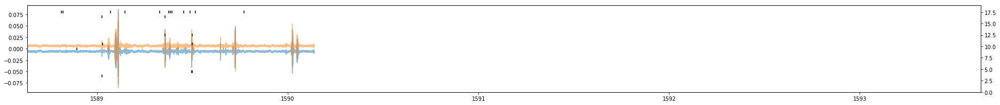

student_song_154
154


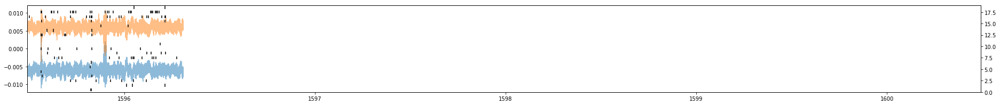

student_song_155
155


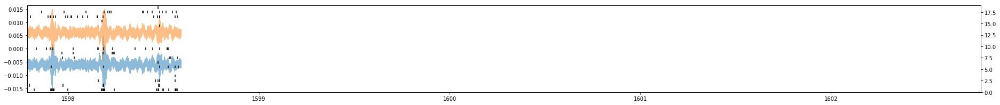

student_song_156
156


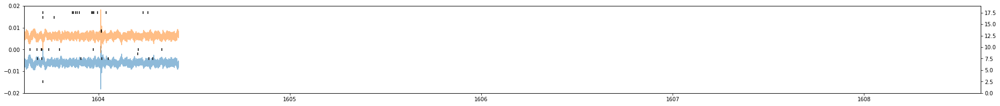

student_song_157
157


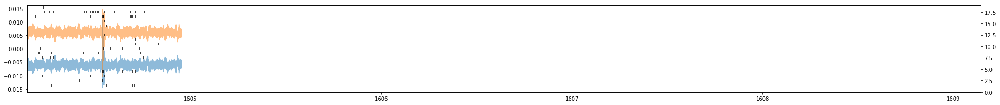

student_song_158
158


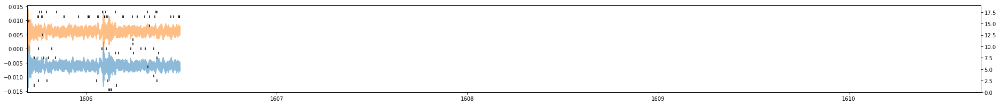

student_song_159
159


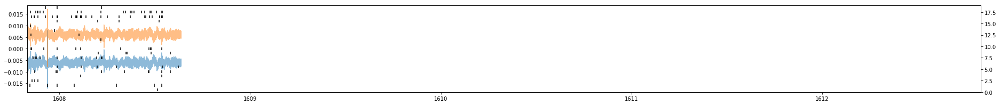

student_song_160
160


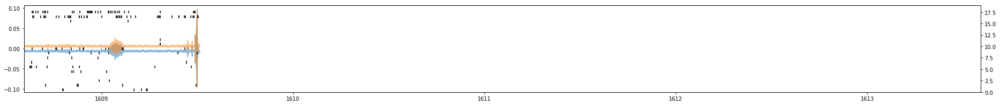

student_song_161
161


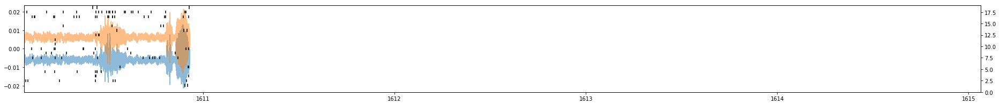

student_song_162
162


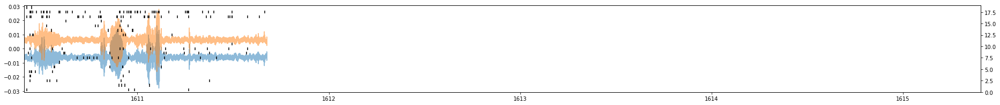

student_song_163
163


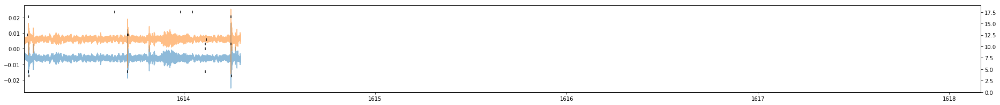

student_song_164
164


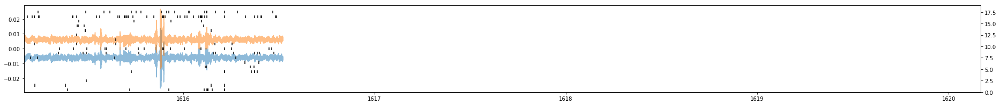

student_song_165
165


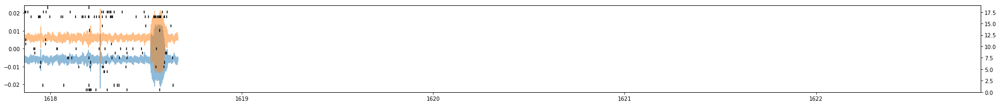

student_song_166
166


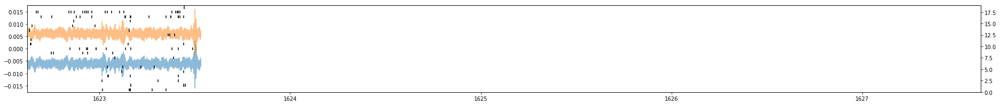

student_song_167
167


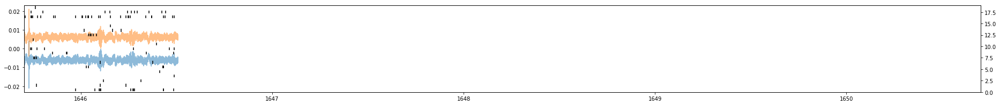

student_song_168
168


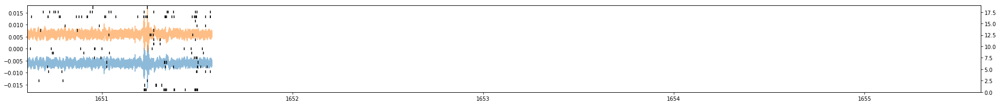

student_song_169
169


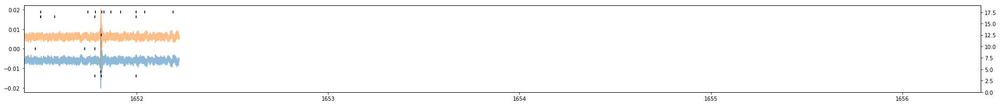

student_song_170
170


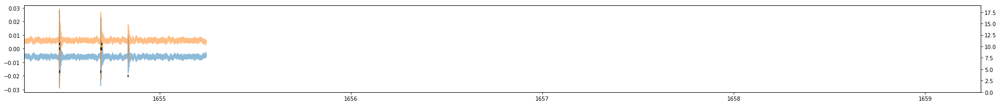

student_song_171
171


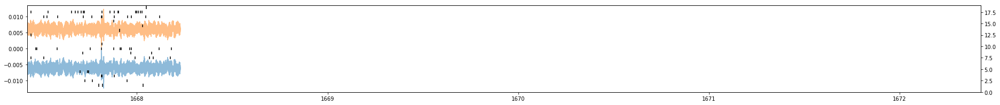

student_song_172
172


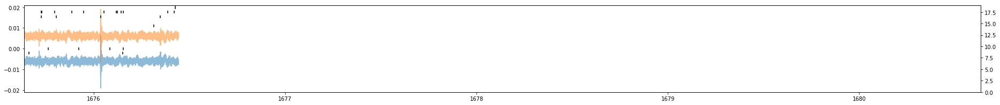

student_song_173
173


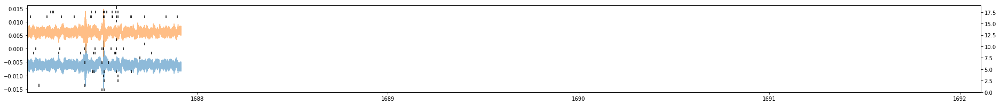

student_song_174
174


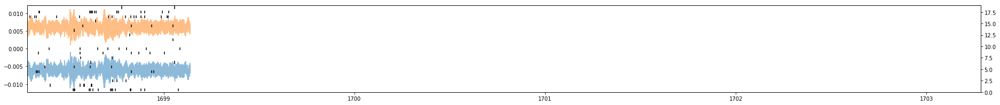

student_song_175
175


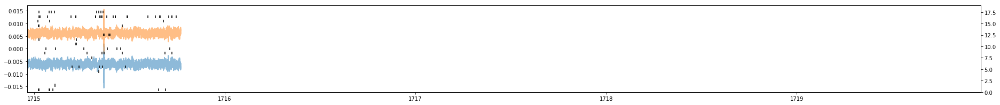

student_song_176
176


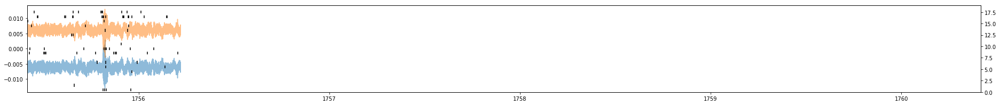

student_song_177
177


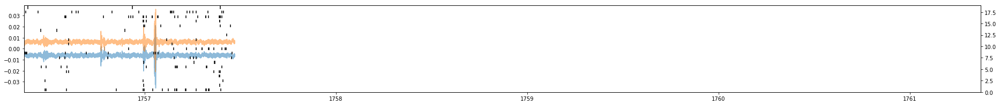

student_song_178
178


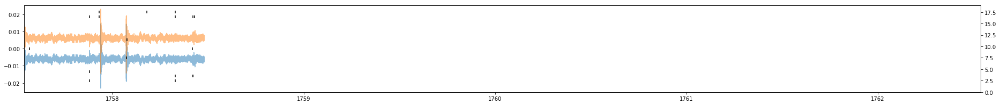

student_song_179
179


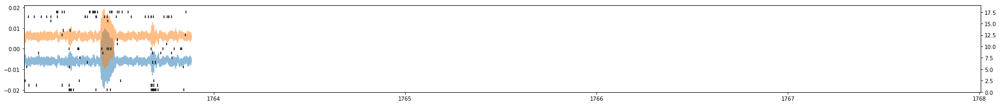

student_song_180
180


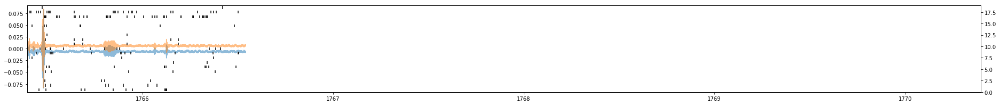

student_song_181
181


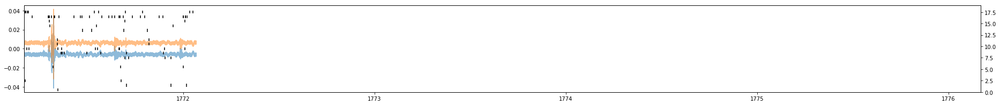

student_song_182
182


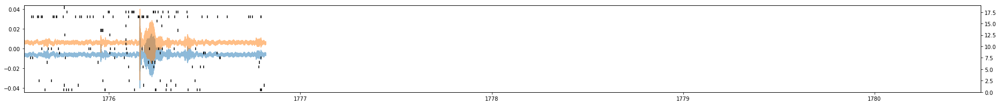

student_song_183
183


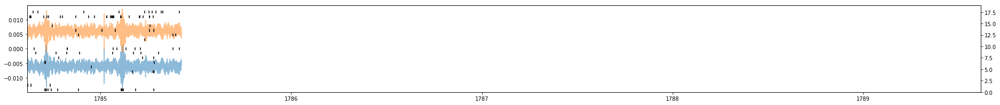

student_song_184
184


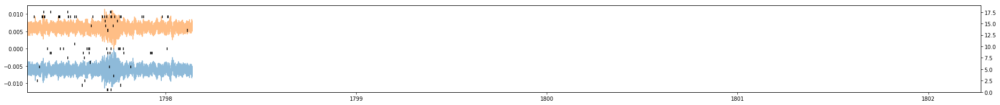

student_song_185
185


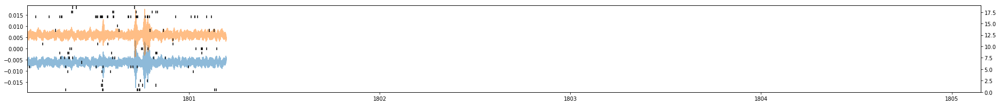

student_song_186
186


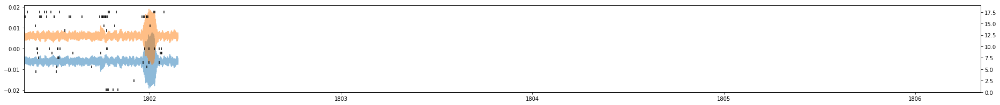

student_song_187
187


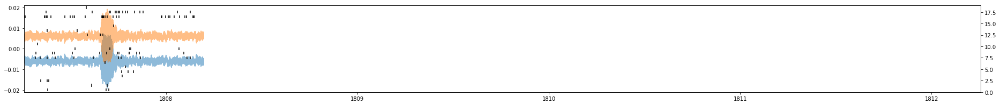

student_song_188
188


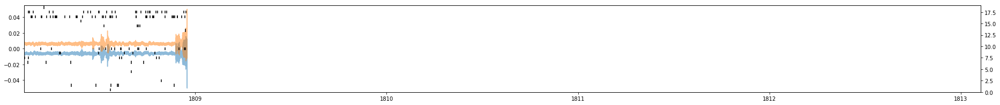

student_song_189
189


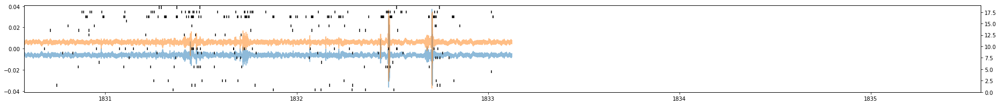

student_song_190
190


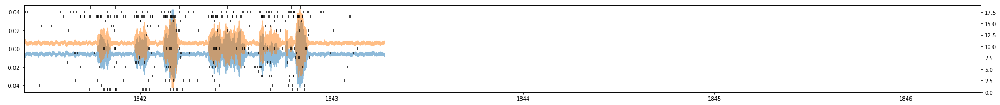

student_song_191
191


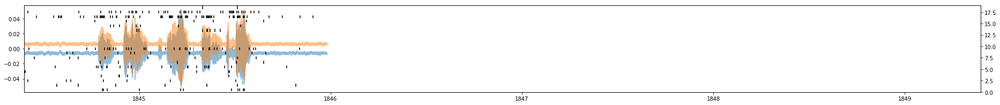

student_song_192
192


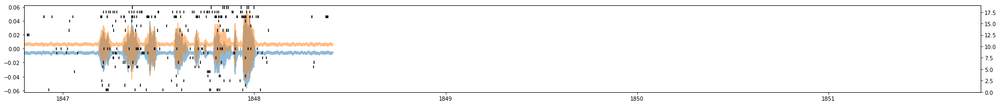

student_song_193
193


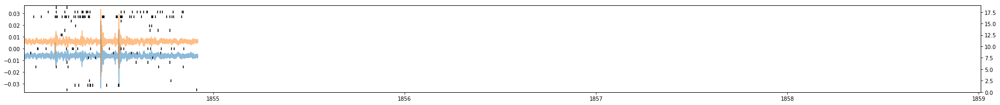

student_song_194
194


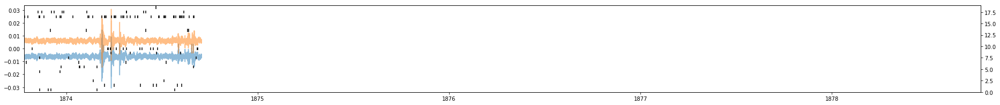

student_song_195
195


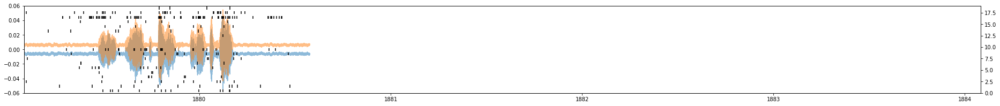

student_song_196
196


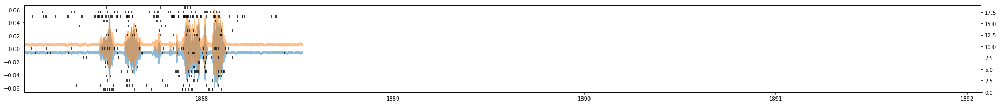

student_song_197
197


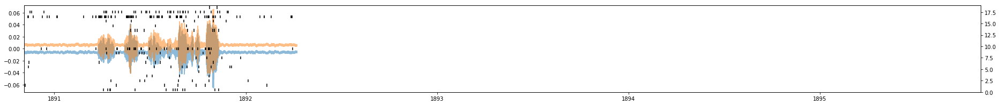

student_song_198
198


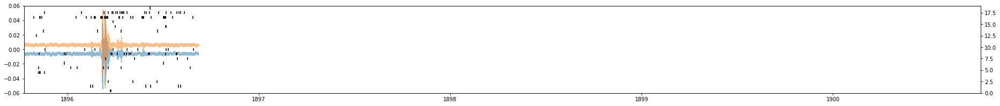

student_song_199
199


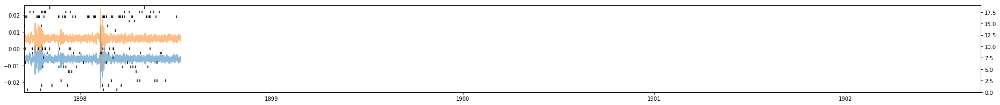

student_song_200
200


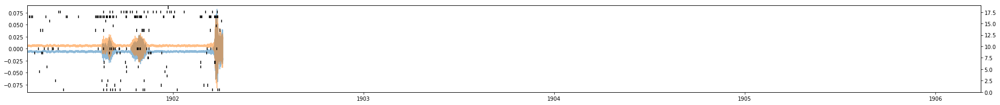

student_song_201
201


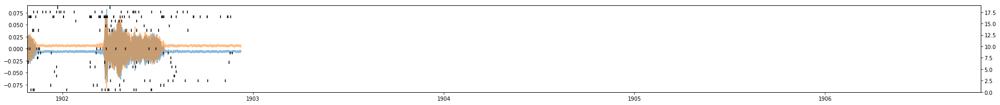

student_song_202
202


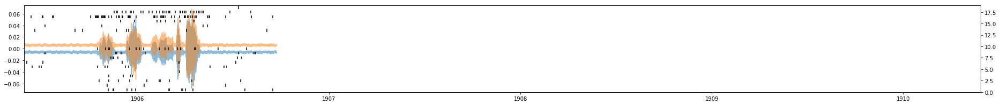

student_song_203
203


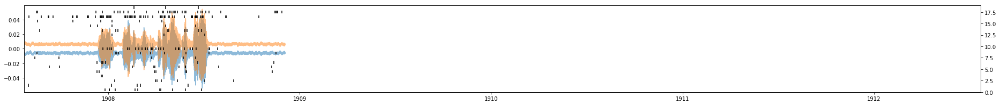

student_song_204
204


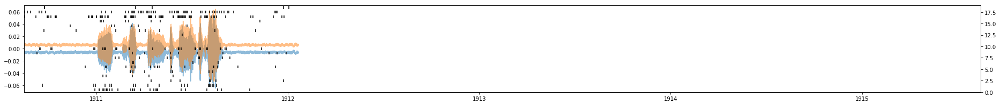

student_song_205
205


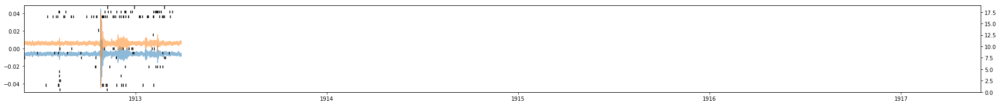

student_song_206
206


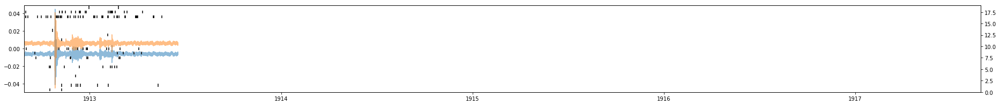

student_song_207
207


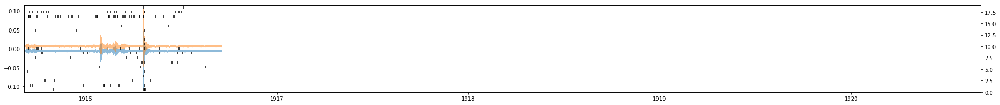

student_song_208
208


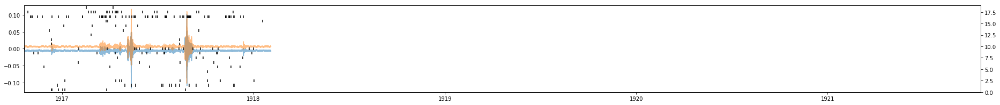

student_song_209
209


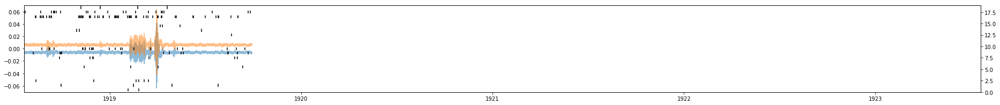

student_song_210
210


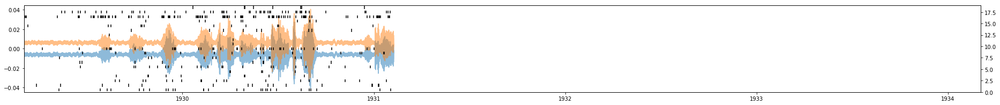

student_song_211
211


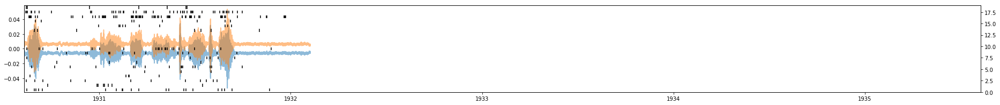

student_song_212
212


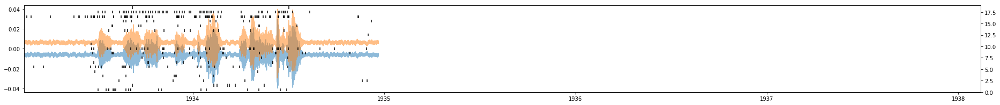

student_song_213
213


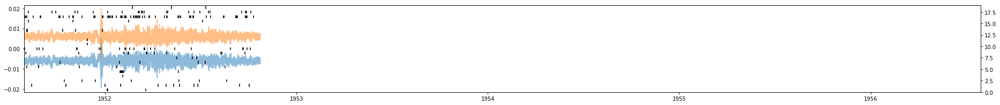

student_song_214
214


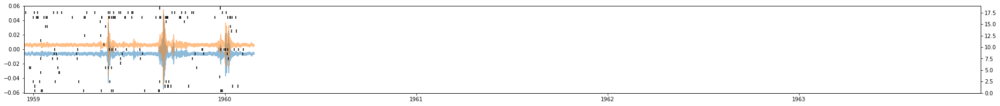

student_song_215
215


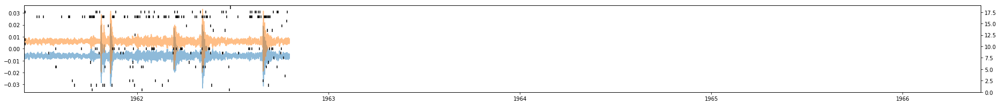

student_song_216
216


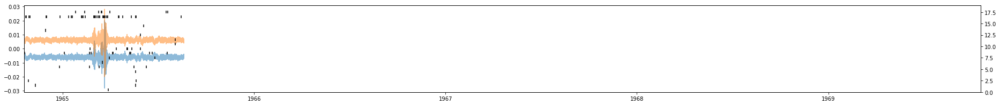

student_song_217
217


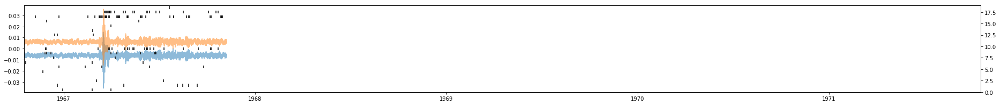

student_song_218
218


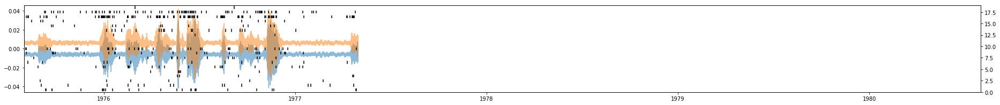

student_song_219
219


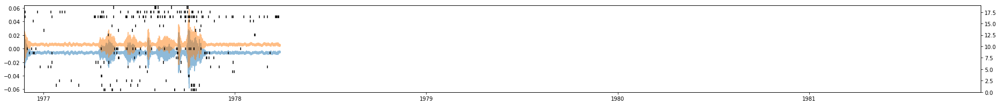

student_song_220
220


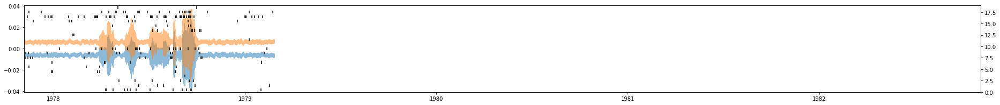

student_song_221
221


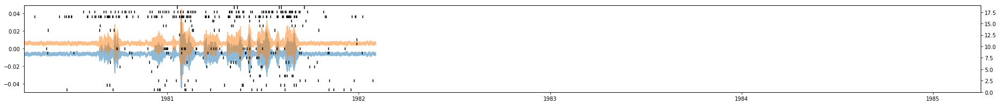

student_song_222
222


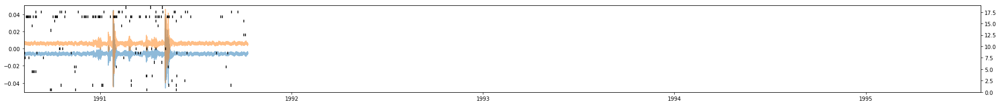

student_song_223
223


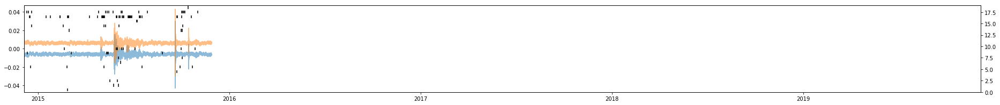

student_song_224
224


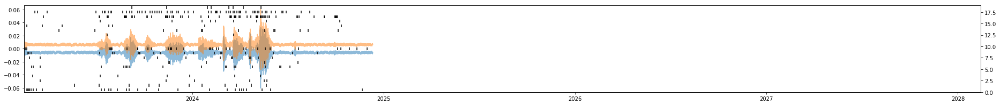

student_song_225
225


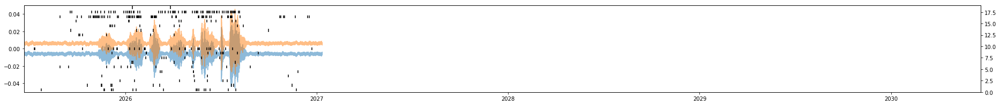

student_song_226
226


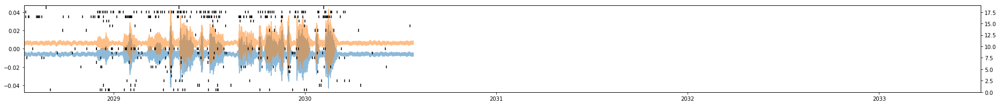

student_song_227
227


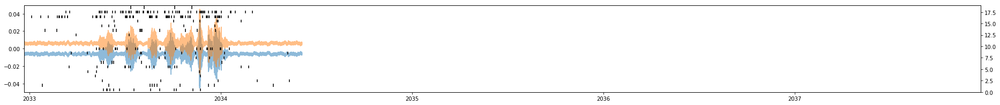

student_song_228
228


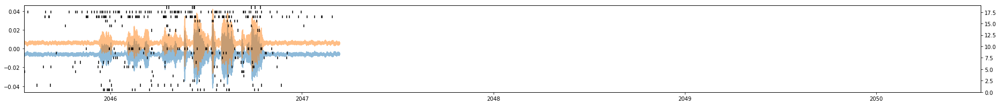

student_song_229
229


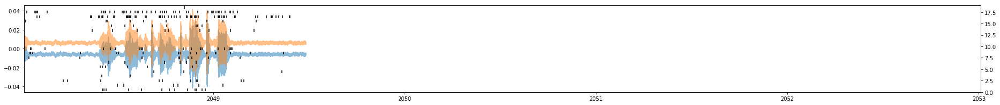

student_song_230
230


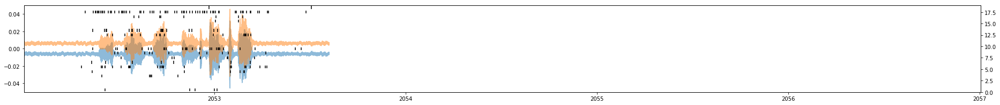

student_song_231
231


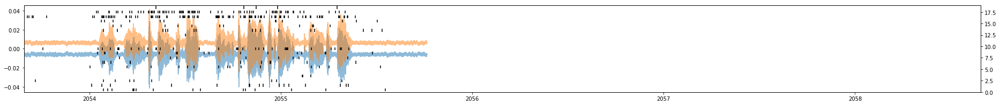

student_song_232
232


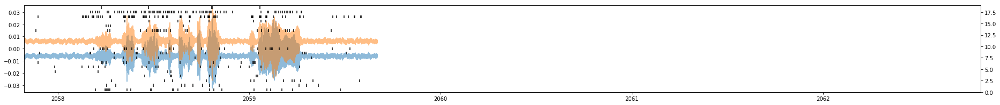

student_song_233
233


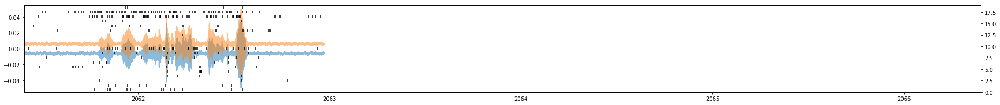

student_song_234
234


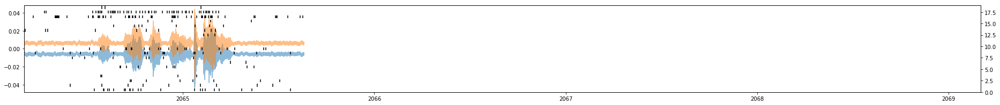

student_song_235
235


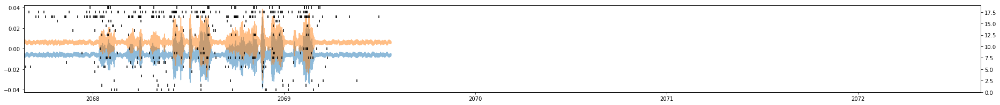

student_song_236
236


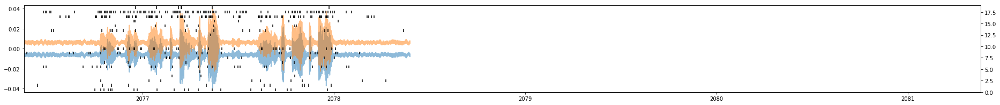

student_song_237
237


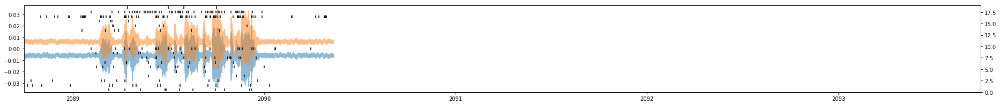

student_song_238
238


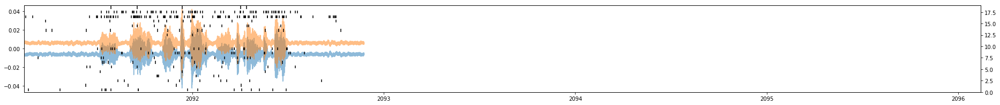

student_song_239
239


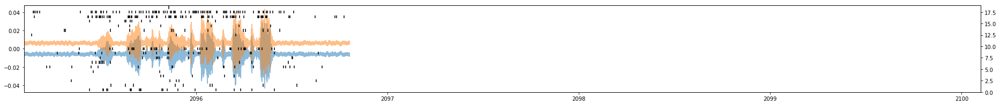

student_song_240
240


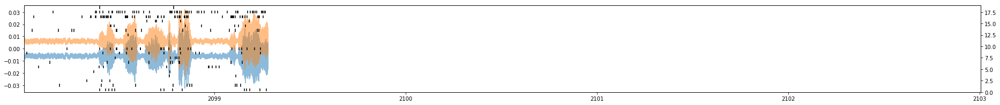

student_song_241
241


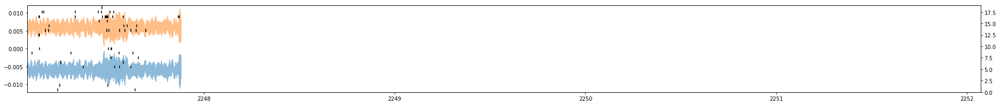

student_song_242
242


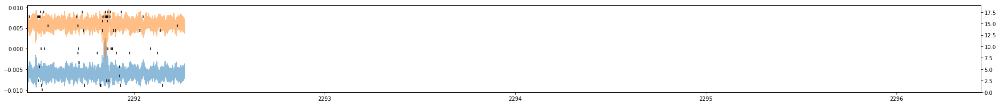

student_song_243
243


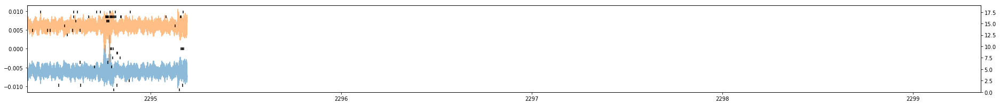

student_song_244
244


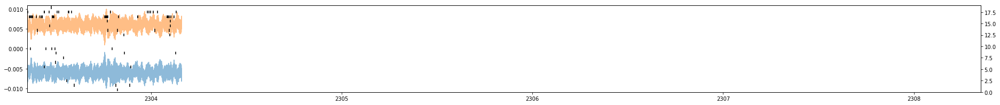

student_song_245
245


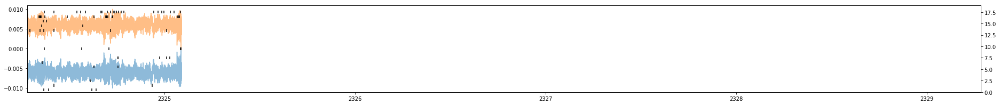

student_song_246
246


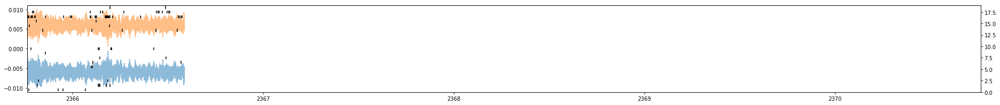

student_song_247
247


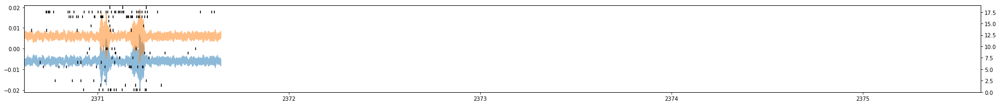

student_song_248
248


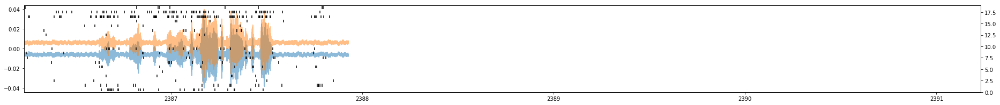

student_song_249
249


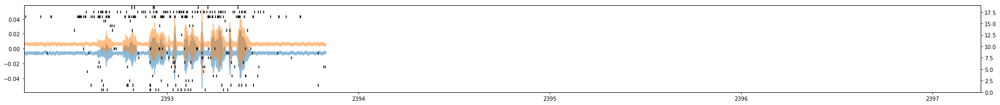

student_song_250
250


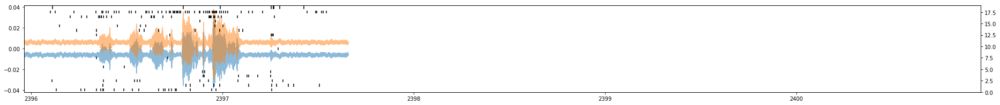

student_song_251
251


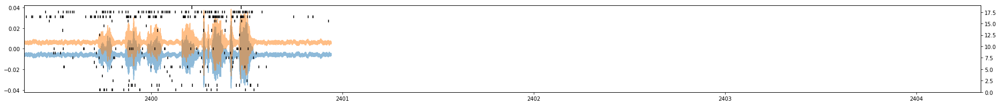

student_song_252
252


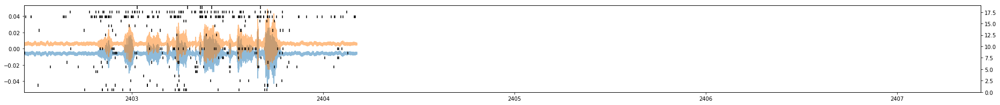

student_song_253
253


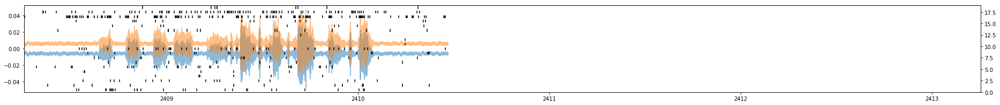

student_song_254
254


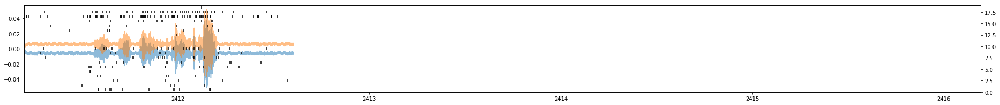

student_song_255
255


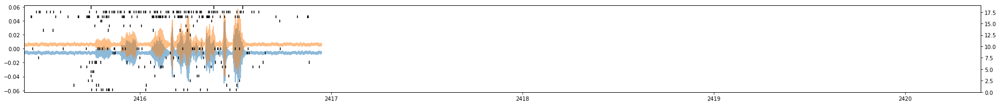

student_song_256
256


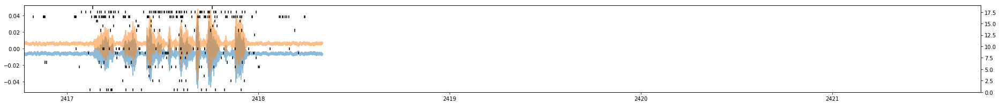

student_song_257
257


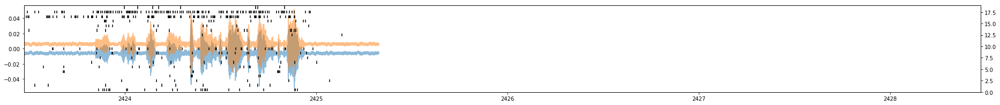

student_song_258
258


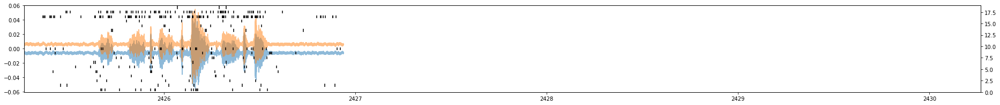

student_song_259
259


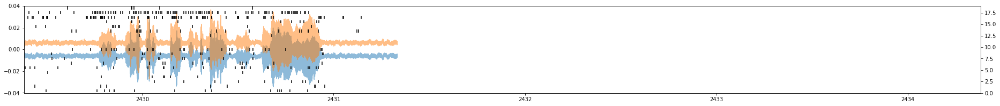

student_song_260
260


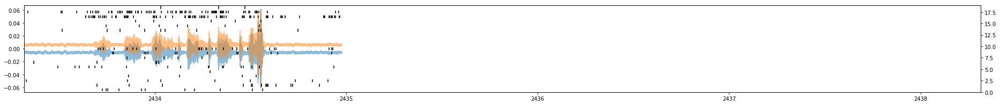

student_song_261
261


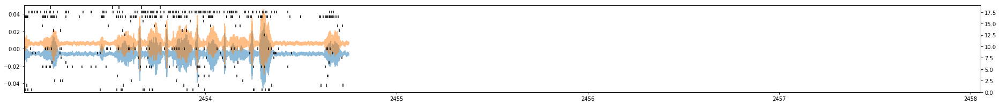

student_song_262
262


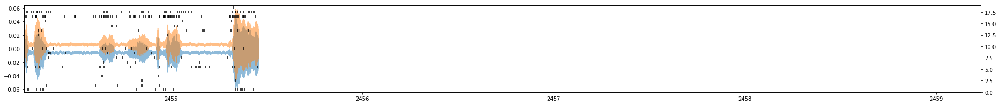

student_song_263
263


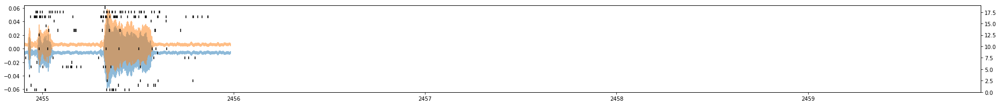

student_song_264
264


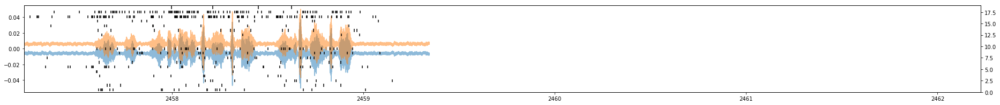

student_song_265
265


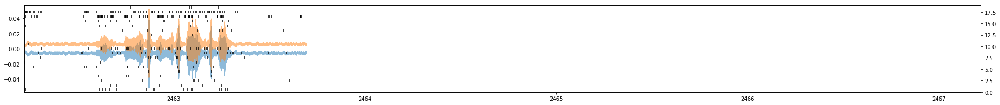

student_song_266
266


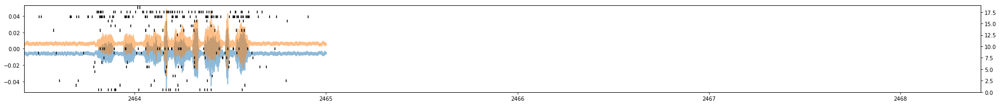

student_song_267
267


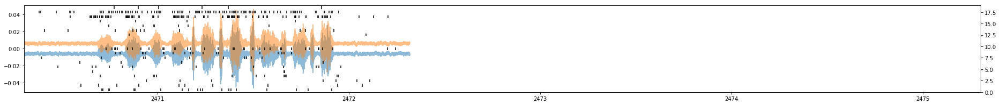

student_song_268
268


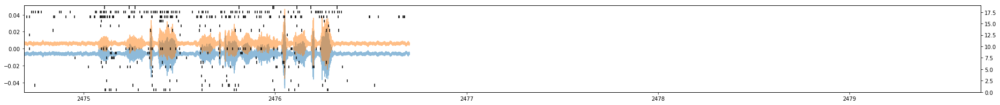

student_song_269
269


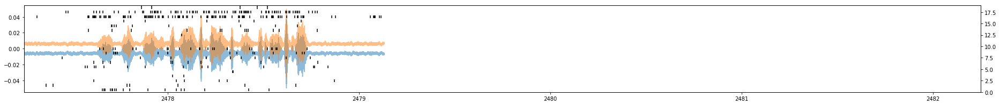

student_song_270
270


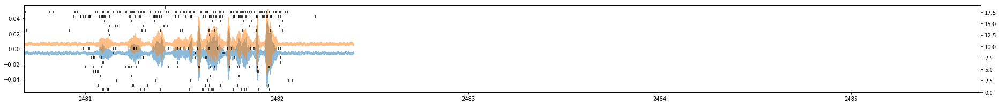

student_song_271
271


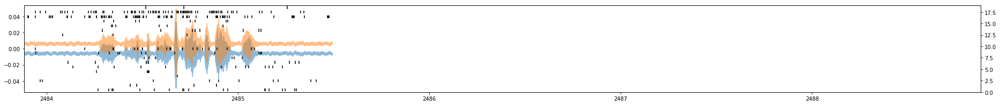

student_song_272
272


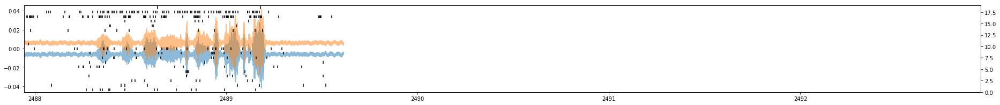

student_song_273
273


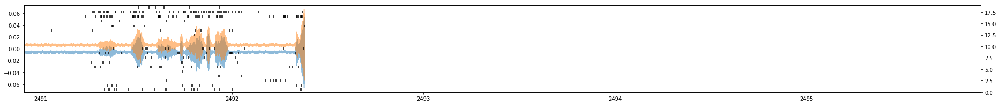

student_song_274
274


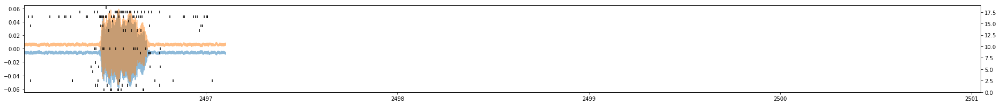

student_song_275
275


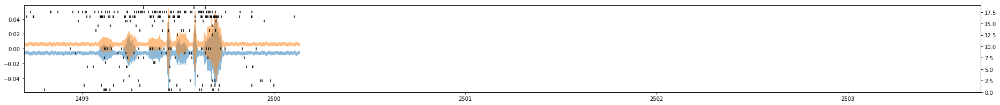

student_song_276
276


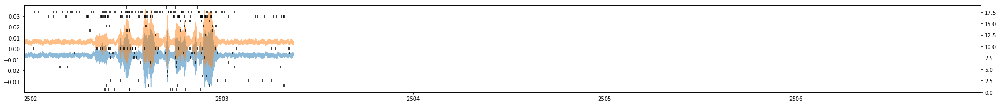

student_song_277
277


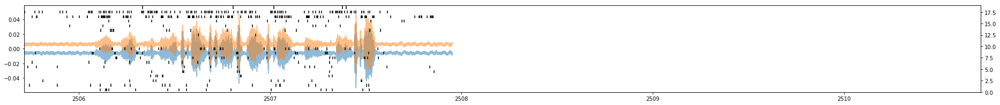

student_song_278
278


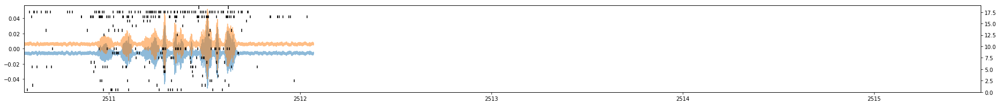

student_song_279
279


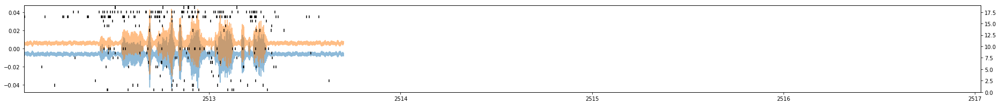

student_song_280
280


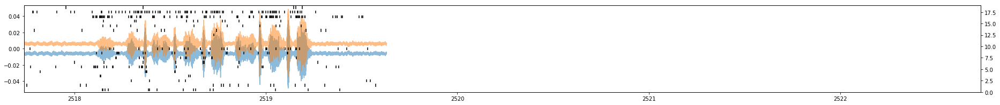

student_song_281
281


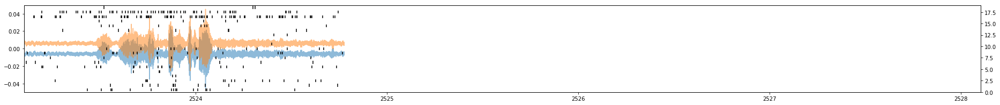

student_song_282
282


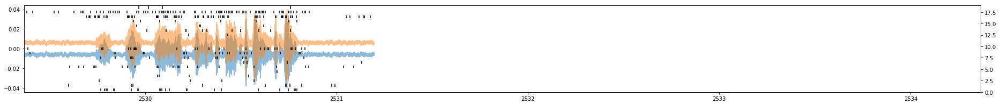

student_song_283
283


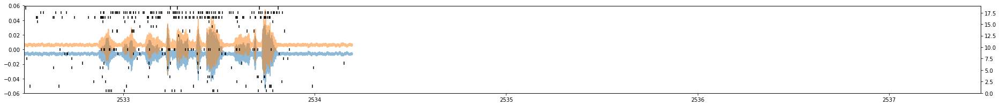

student_song_284
284


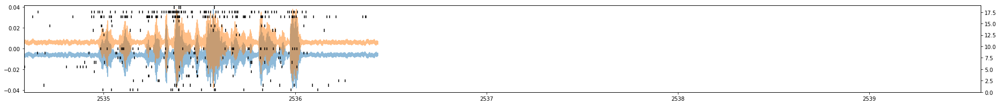

student_song_285
285


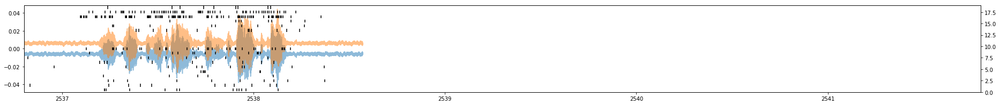

student_song_286
286


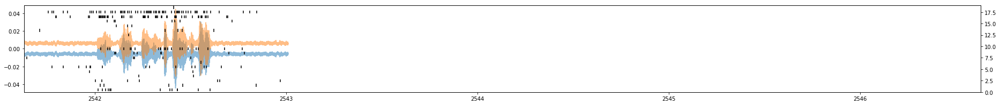

student_song_287
287


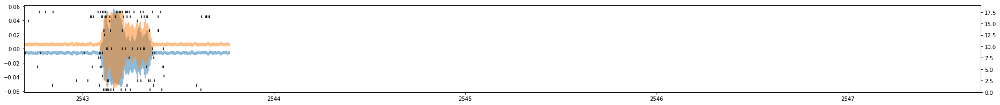

student_song_288
288


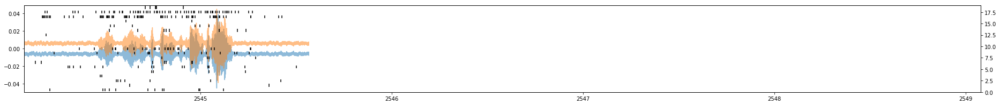

student_song_289
289


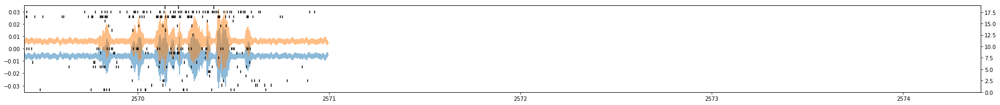

student_song_290
290


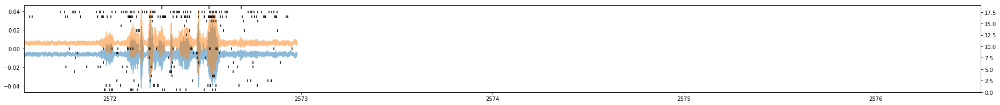

student_song_291
291


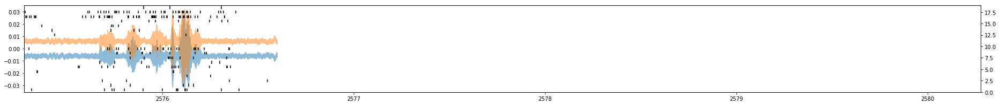

student_song_292
292


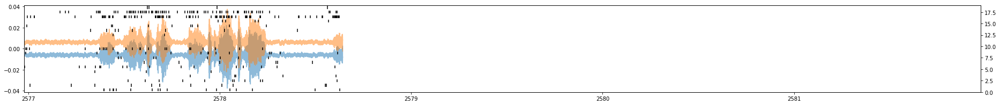

student_song_293
293


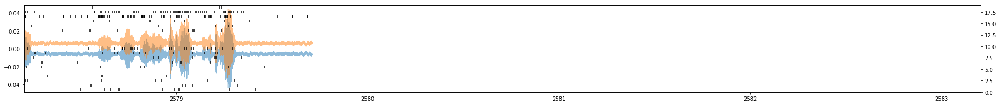

student_song_294
294


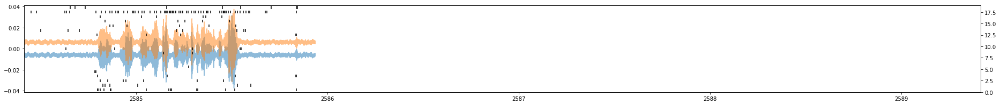

student_song_295
295


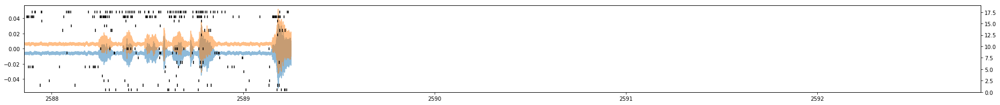

student_song_296
296


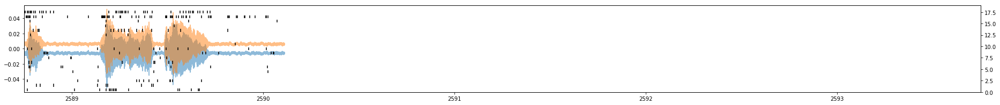

student_song_297
297


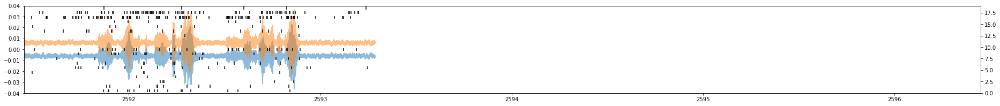

student_song_298
298


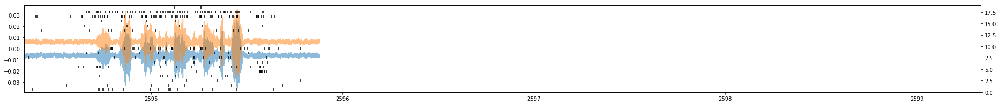

student_song_299
299


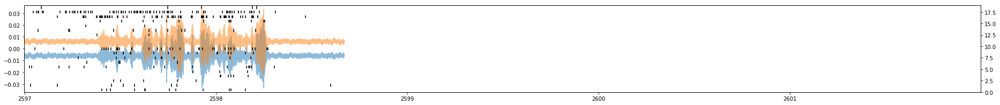

student_song_300
300


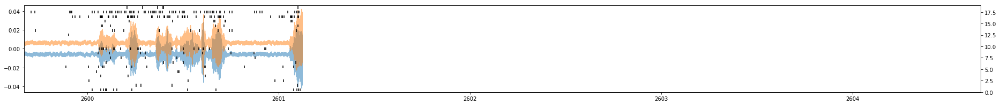

student_song_301
301


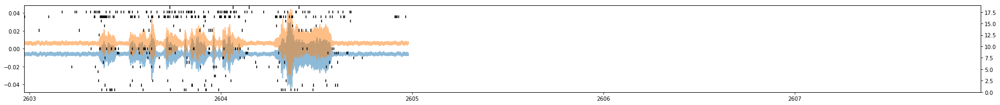

student_song_302
302


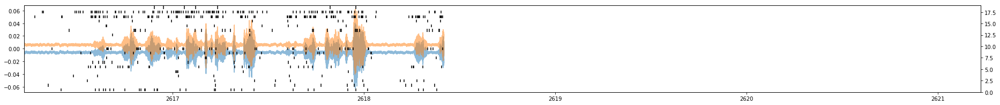

student_song_303
303


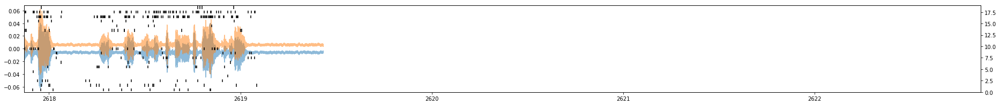

student_song_304
304


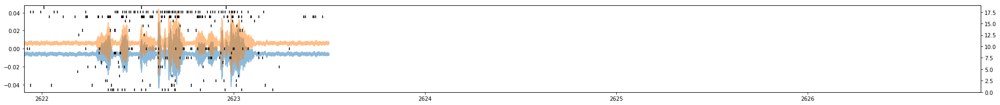

student_song_305
305


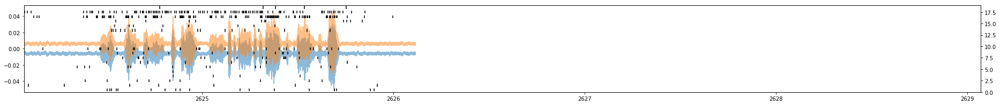

student_song_306
306


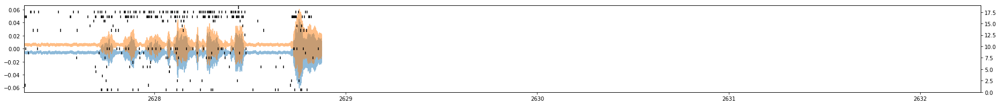

student_song_307
307


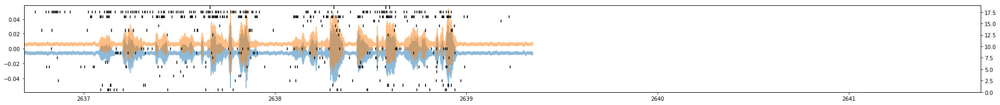

student_song_308
308


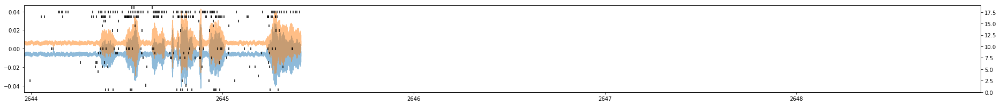

student_song_309
309


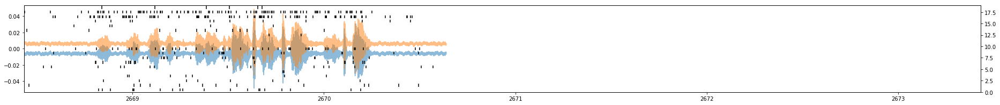

student_song_310
310


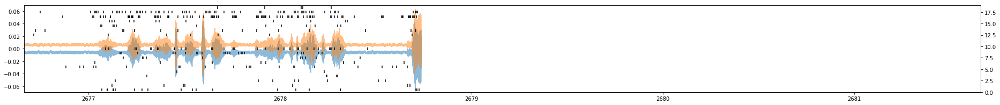

student_song_311
311


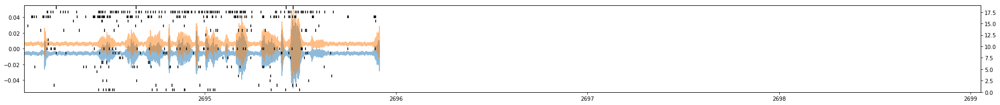

student_song_312
312


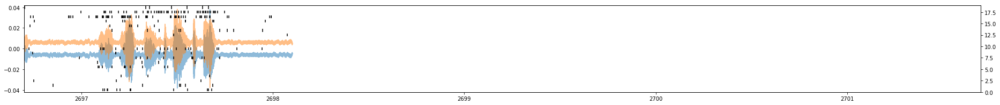

student_song_313
313


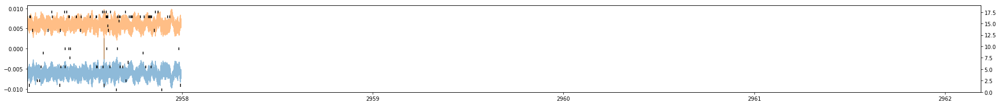

student_song_314
314


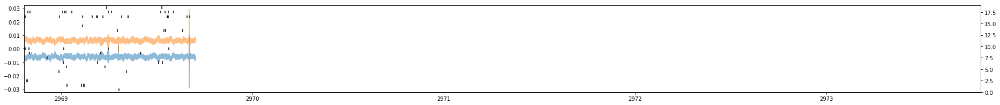

student_song_315
315


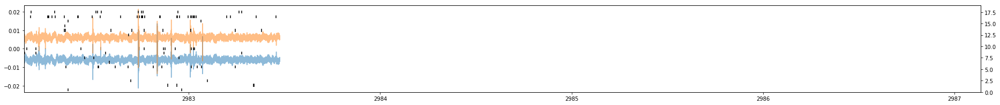

student_song_316
316


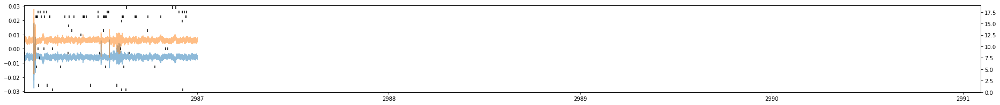

student_song_317
317


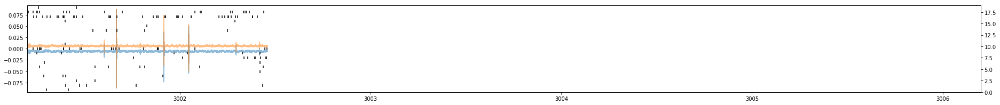

student_song_318
318


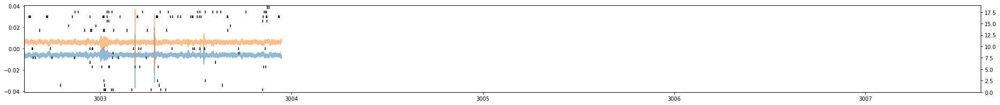

student_song_319
319


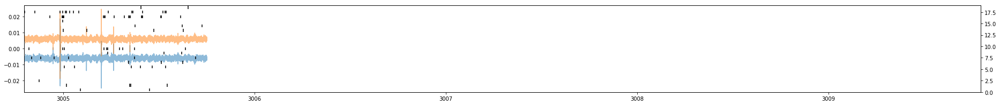

student_song_320
320


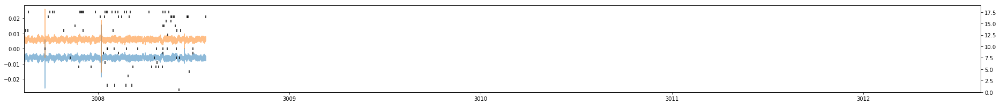

student_song_321
321


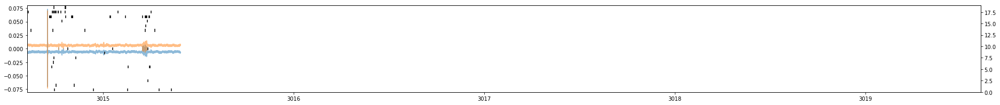

student_song_322
322


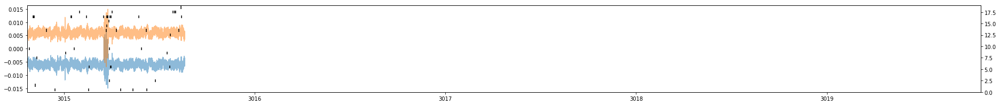

student_song_323
323


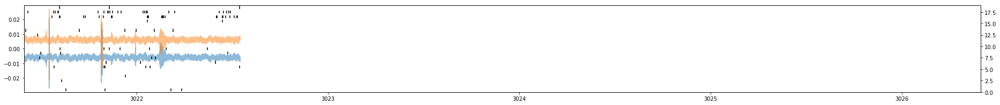

student_song_324
324


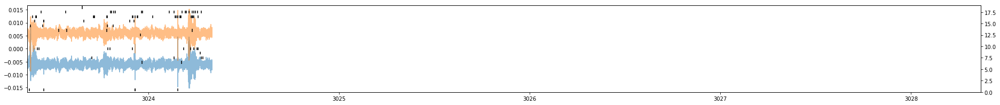

student_song_325
325


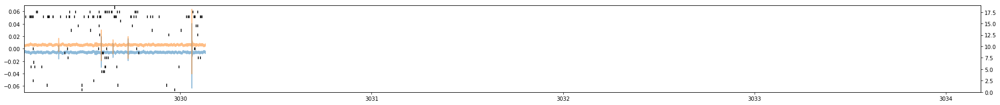

student_song_326
326


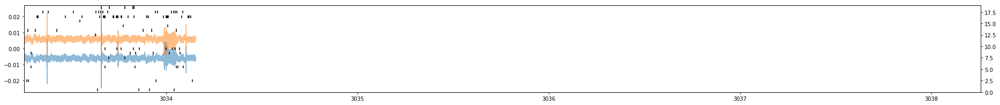

student_song_327
327


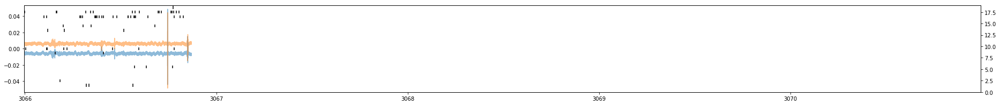

student_song_328
328


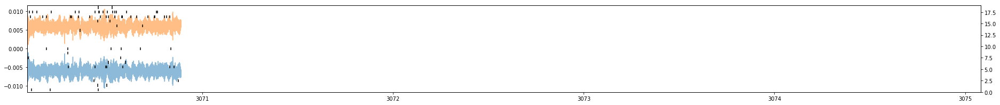

student_song_329
329


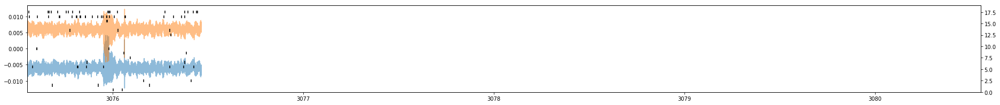

student_song_330
330


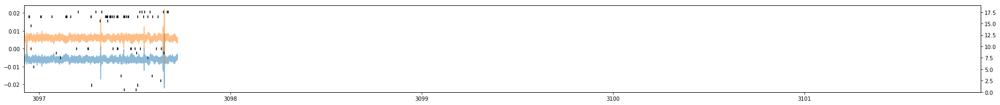

student_song_331
331


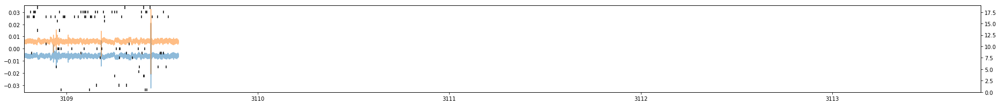

student_song_332
332


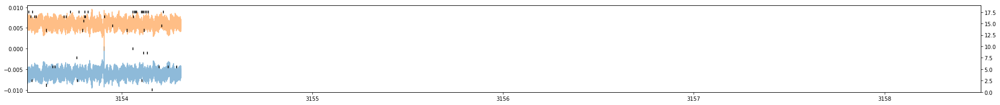

student_song_333
333


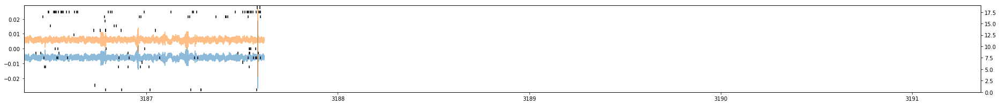

student_song_334
334


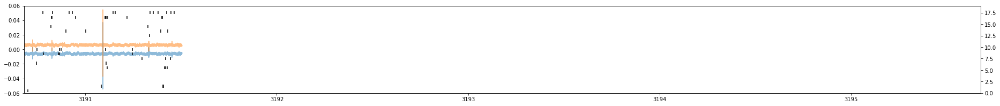

student_song_335
335


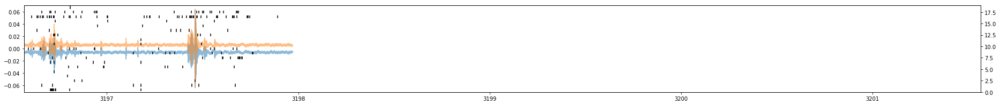

student_song_336
336


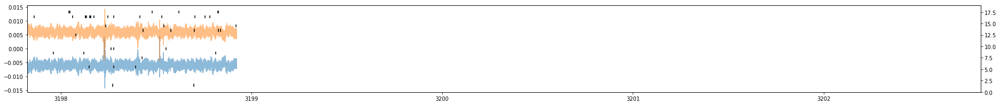

student_song_337
337


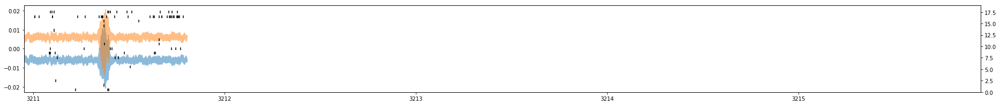

student_song_338
338


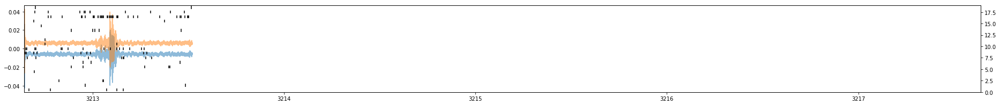

student_song_339
339


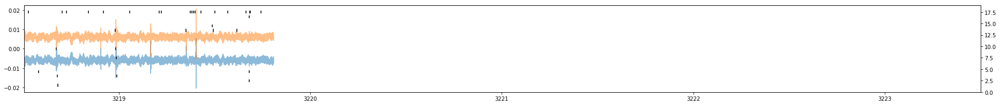

student_song_340
340


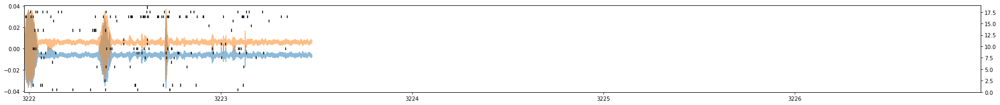

student_song_341
341


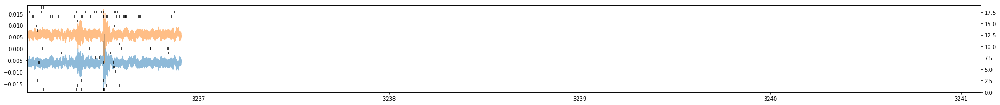

student_song_342
342


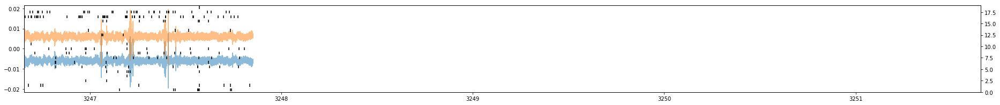

student_song_343
343


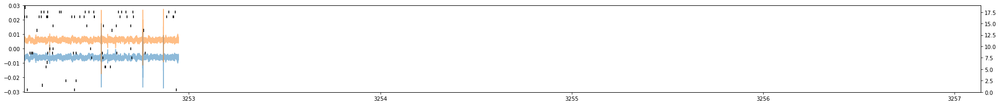

student_song_344
344


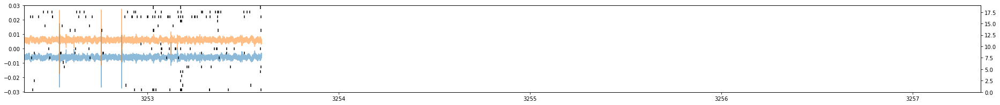

student_song_345
345


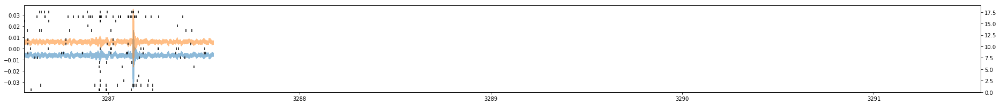

student_song_346
346


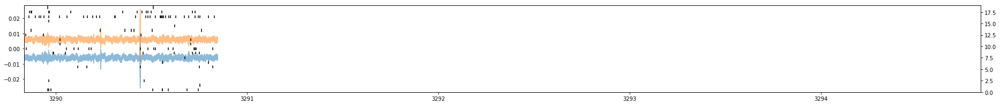

student_song_347
347


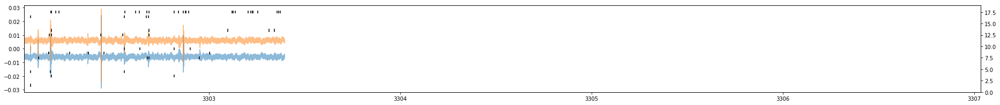

student_song_348
348


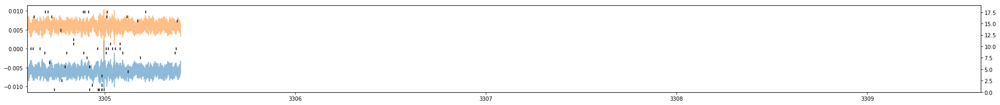

student_song_349
349


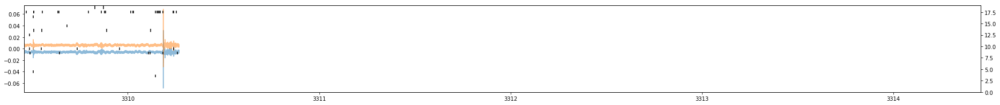

student_song_350
350


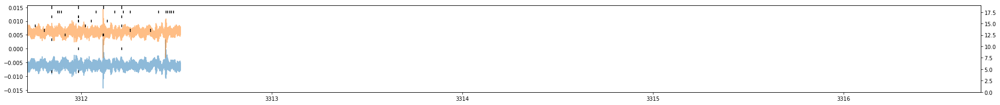

student_song_351
351


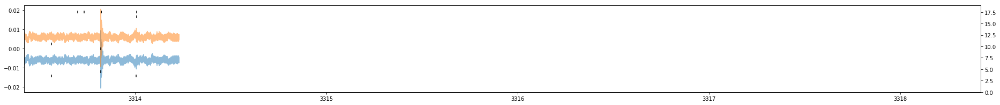

student_song_352
352


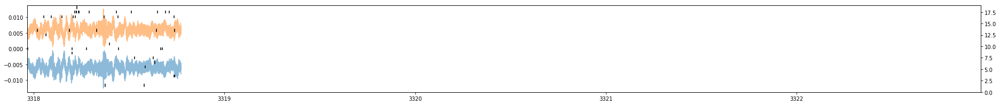

student_song_353
353


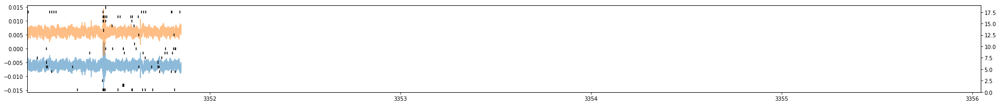

student_song_354
354


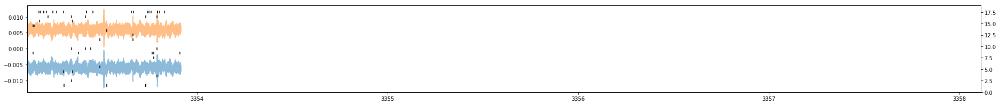

student_song_355
355


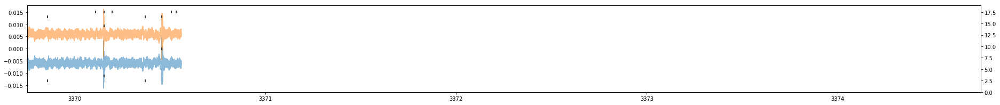

student_song_356
356


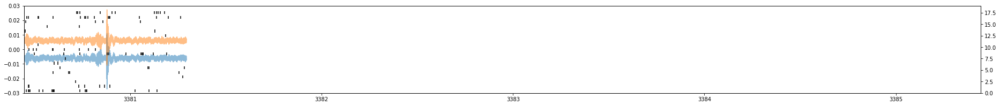

student_song_357
357


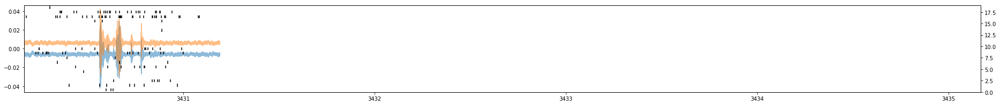

student_song_358
358


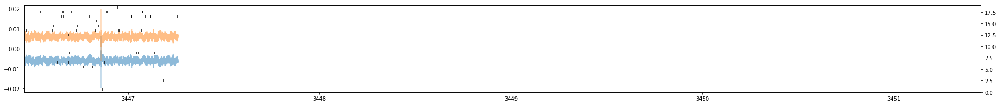

student_song_359
359


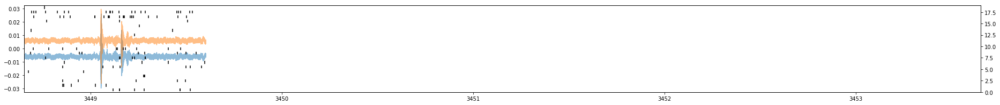

student_song_360
360


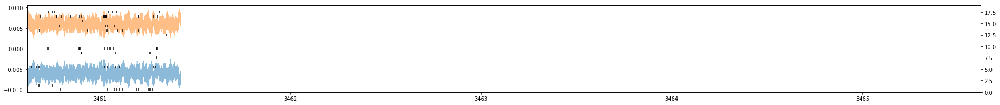

student_song_361
361


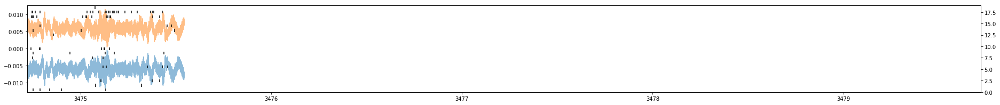

student_song_362
362


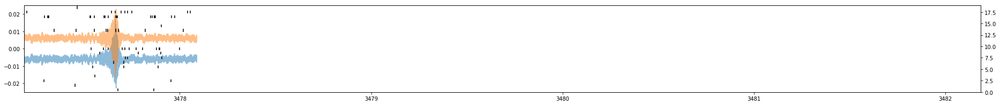

student_song_363
363


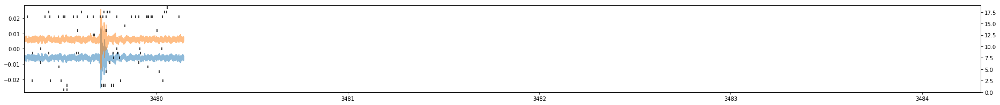

student_song_364
364


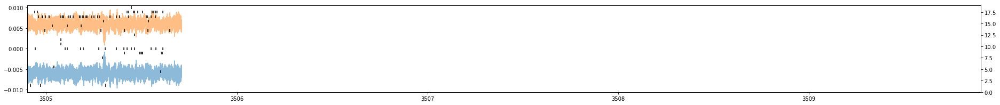

student_song_365
365


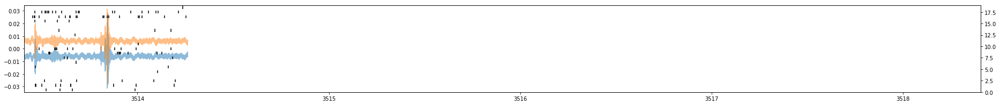

student_song_366
366


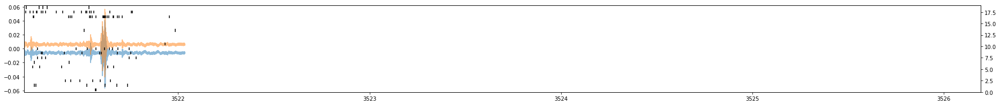

student_song_367
367


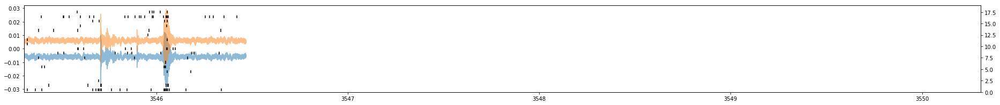

student_song_368
368


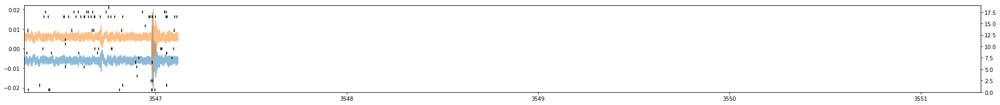

student_song_369
369


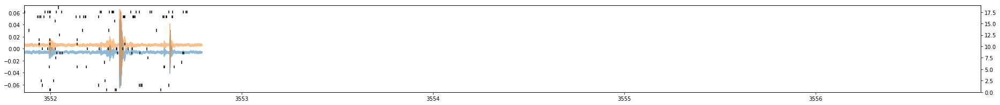

student_song_370
370


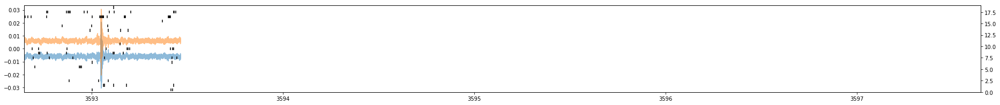

student_song_371
371


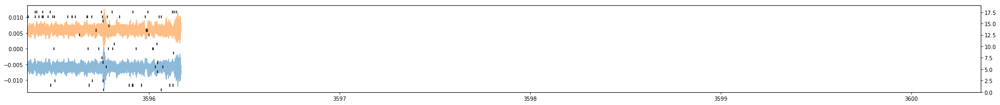

student_song_372
372


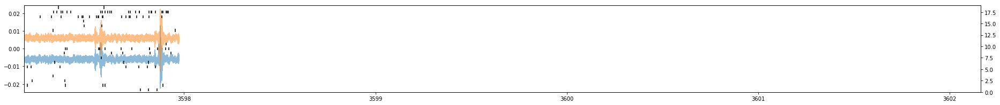

student_song_373
373


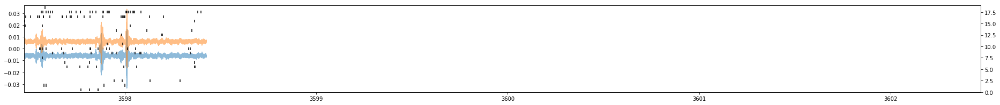

student_song_374
374


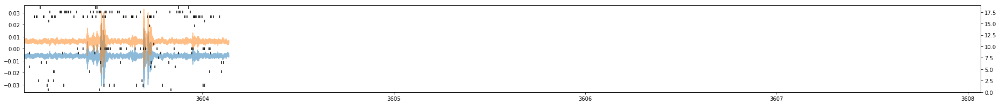

student_song_375
375


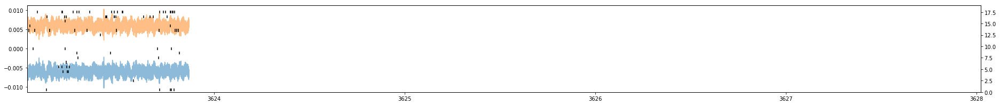

student_song_376
376


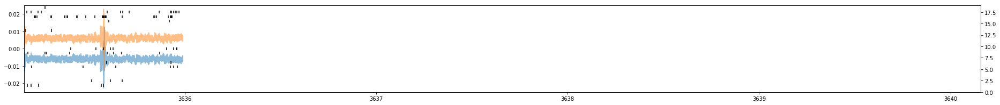

student_song_377
377


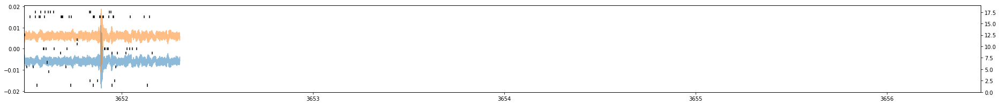

student_song_378
378


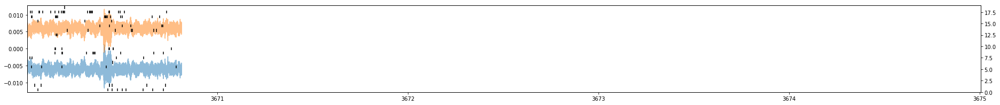

student_song_379
379


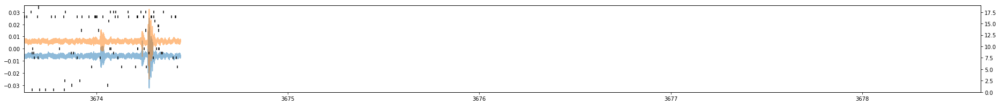

student_song_380
380


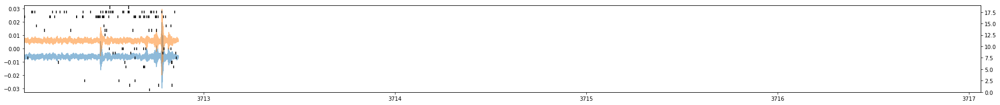

student_song_381
381


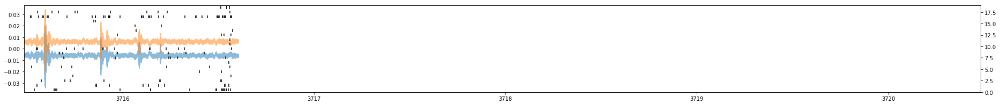

student_song_382
382


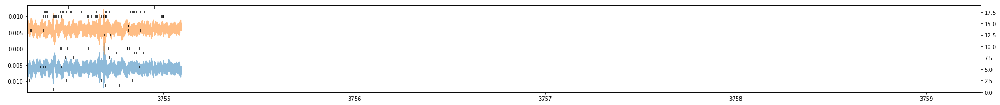

student_song_383
383


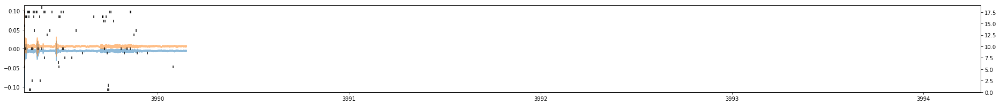

student_song_384
384


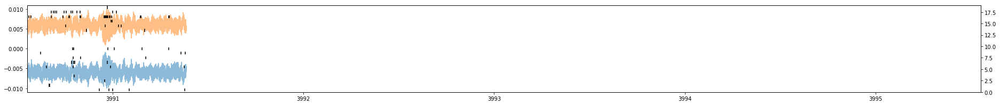

student_song_385
385


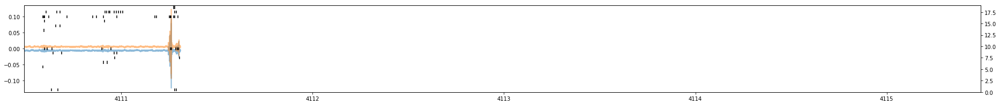

student_song_386
386


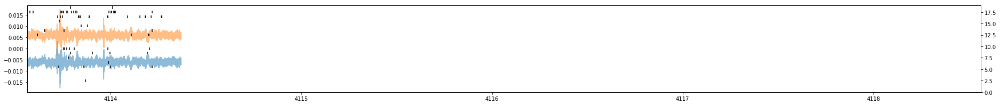

student_song_387
387


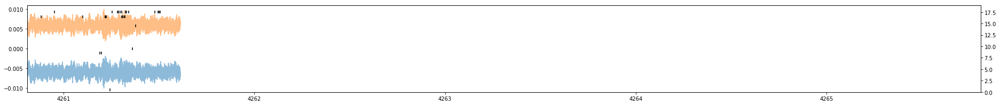

student_song_388
388


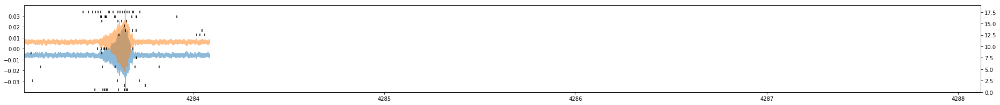

student_song_389
389


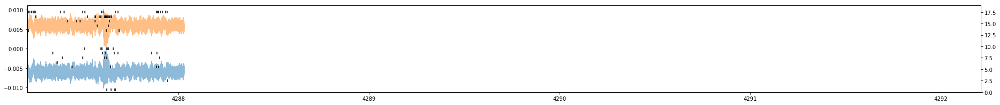

student_song_390
390


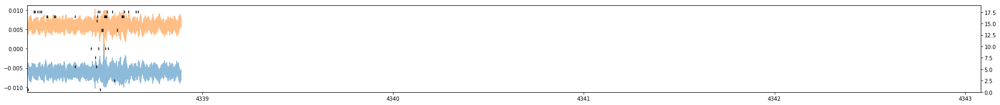

student_song_391
391


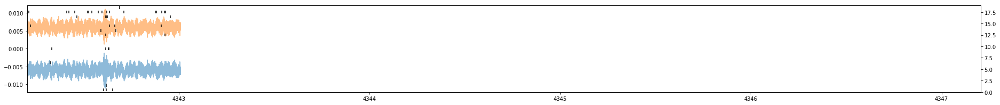

student_song_392
392


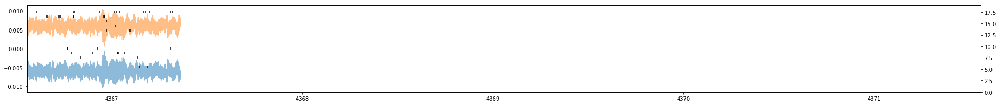

student_song_393
393


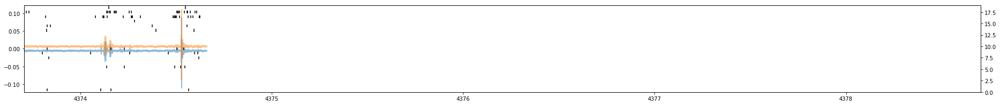

student_song_394
394


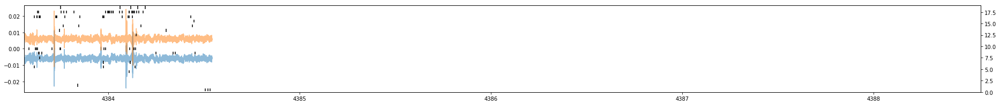

student_song_395
395


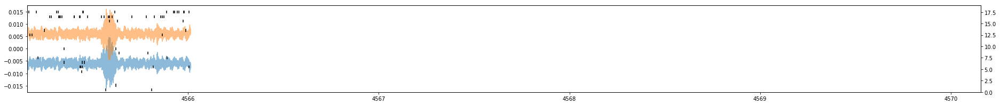

student_song_396
396


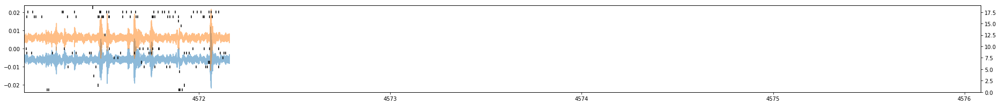

student_song_397
397


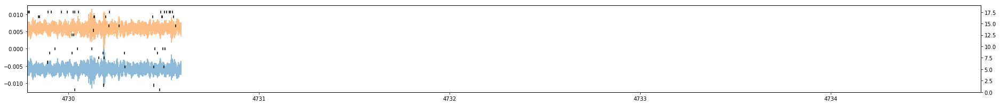

student_song_398
398


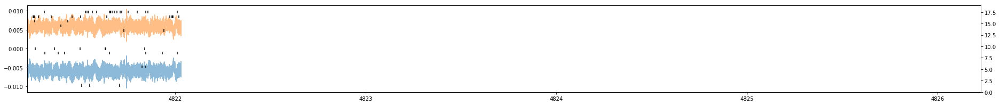

student_song_399
399


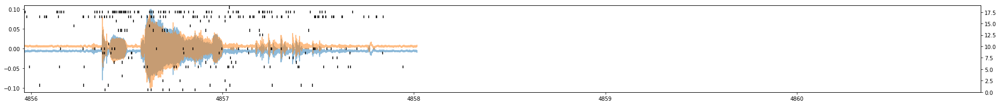

student_song_400
400


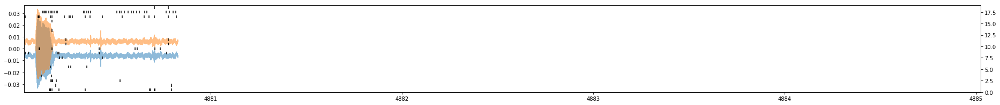

student_song_401
401


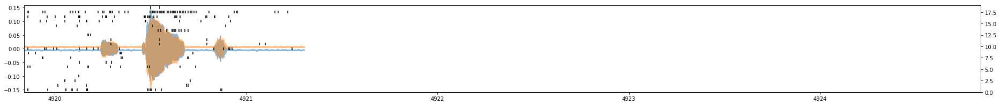

student_song_402
402


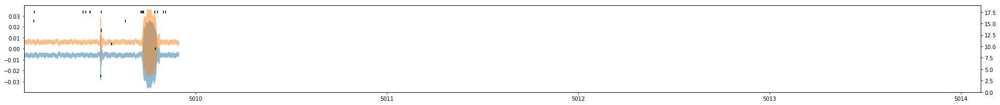

student_song_403
403


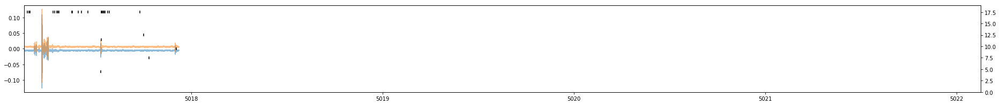

student_song_404
404


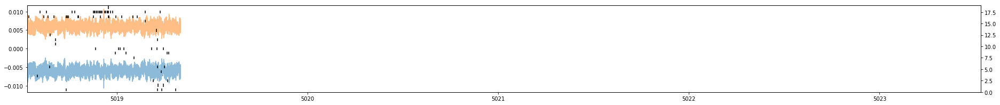

student_song_405
405


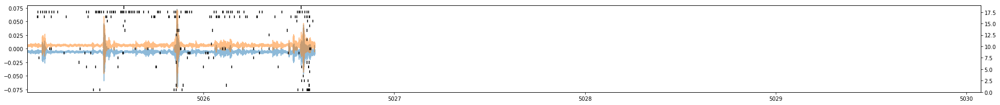

student_song_406
406


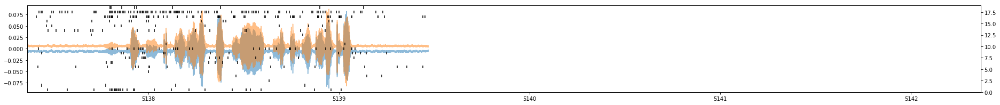

student_song_407
407


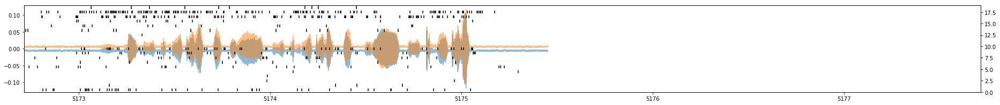

tutor_song_0
408


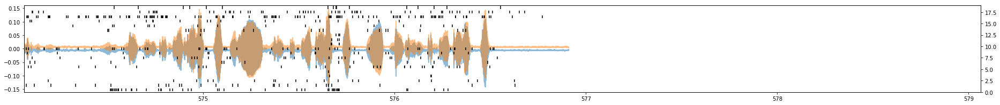

tutor_song_1
409


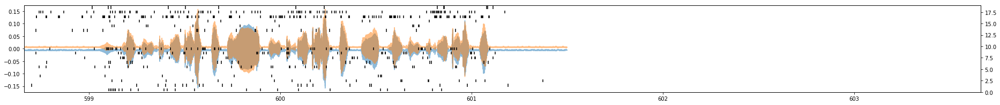

tutor_song_2
410


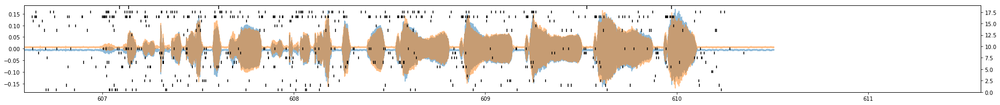

tutor_song_3
411


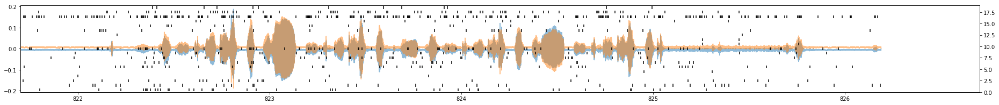

tutor_song_4
412


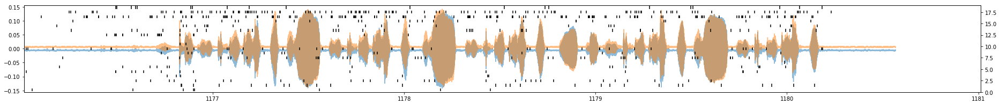

tutor_song_5
413


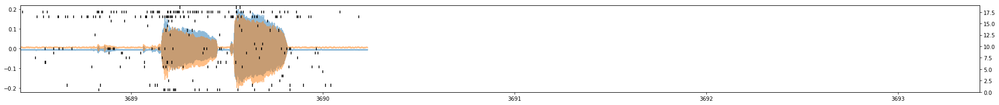

tutor_song_6
414


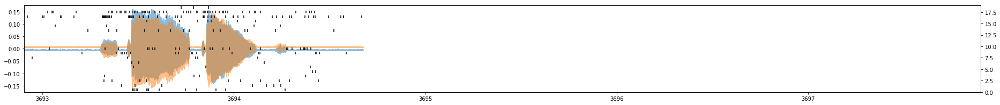

tutor_song_7
415


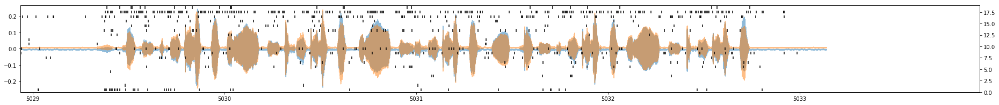

tutor_song_8
416


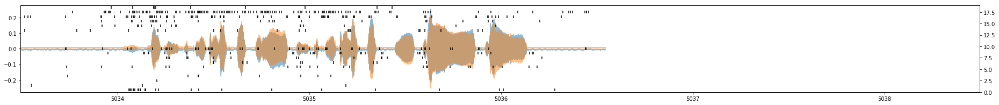

In [33]:
for seg_idx in range(len(block2.segments)):
    
    seg = block2.segments[seg_idx]
    
    print seg.name
    print seg_idx
    
    # here we need to figure out which units look reasonable
    
    spiketrains = [st for st in seg.spiketrains]

    sound = seg.analogsignals[0].as_array()[:, 0]
    sound1 = seg.analogsignals[0].as_array()[:, 1]
    fig, ax = plt.subplots(figsize=(32, 3))

    plot_spikes_with_timeseries(
        np.linspace(seg.t_start.item(), seg.t_stop.item(), len(sound)),
        spiketrains,
        seg.analogsignals[0].T - np.mean(seg.analogsignals[0].T, axis=0),
        seg.t_start.item(),
        seg.t_start.item() + 5.0,
        ax=ax,
        spike_alpha=1.0,
        y_alpha=[0.5, 0.5]
    )

    plt.show()

In [41]:
st = block2.channel_indexes[-4].units[0].spiketrains[-1]

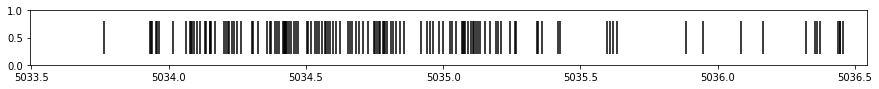

In [56]:
plt.figure(figsize=(15, 1))
raster.plot([st], st.t_start, st.t_stop)
plt.show()

In [58]:
from spikes.utils import bin_spikes

In [86]:
t_arr, spikes = bin_spikes([st.times],
    min_time=st.t_start.item(),
    dt=0.001,
    n_bins=int((st.t_stop - st.t_start).item() / 0.001))

In [88]:
len(spikes)

3048

In [89]:
from __future__ import division

import numpy as np


def gaussian_convolver(std, n=3.0):
    """Create gaussian in an array form extending n std on either side

    Input:
    std (float): std of gaussian distribution
    n (float, default=3.0): number of stds to extend gaussian in each direction

    Output:
    convolver (fn): function that takes an array, and convolves it with a
        gaussian, returning the same sized array as before
    """
    extend = n * np.floor(std)
    t = np.arange(-extend, extend + 1)
    std = float(std)
    gaussian = (
        pow(np.sqrt(2 * np.pi * pow(std, 2)), -1) *
        np.exp(-pow(t, 2) / (2 * pow(std, 2)))

    )
    return lambda d: np.convolve(d, gaussian, mode="same")


def exponential_convolver(tau, n=4.0):
    """Create normalized exponential fn in array form

    Args:
    tau (float): mean of exponential distribution
    n (float, default=4.0): number of means to extend distribution out to

    convolver (fn): return a function that takes an array and convolves
        with exponential of mean tau. returns same size array as input
    """
    t = np.arange(n * tau)
    result = np.exp(-t / float(tau))
    exp = result / np.sum(result)

    # need to cut off the end since full will extend the last exponential
    # past the end

    return lambda d: np.convolve(d, exp, mode="full")[:d.size]


def conv(data, convolver, *convolver_args, **convolver_kwargs):
    """Convolve an exponential with all rows in the dataset

    Args:
    data (N_samples x N_dim):
        array of datapoint coordinates
    convolver (fn)
        Use either gaussianConvolver or expConvolver
        This function takes args and returns an array for convolution
    *convolver_args (*args)
        Arguments to pass to convolver, i.e. tau for expConvolver

    Returns:
    convolved_data (N_samples, N_dim):
        array of datapoint coordinates after convolving
    """
    return np.apply_along_axis(
            convolver(*convolver_args, **convolver_kwargs), 1, data)



In [100]:
convolved = conv(spikes.T, gaussian_convolver, 50.0)

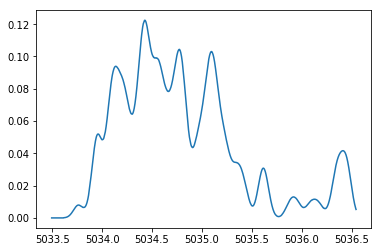

In [101]:
plt.plot(t_arr, convolved[0])
plt.show()

In [103]:
student_rates = []
tutor_rates = []

for seg_idx in range(len(block.segments)):
    
    seg = block.segments[seg_idx]
    
    print seg.name
    print seg_idx
    
    # here we need to figure out which units look reasonable
    
    spiketrains = [st for st in seg.spiketrains]
    dt = (seg.t_stop - seg.t_start).item()
    rates = [len(st) / dt for st in spiketrains]
    
    if seg.name.startswith("student_song"):
        student_rates.append(rates)
    elif seg.name.startswith("tutor_song"):
        tutor_rates.append(rates)
        
student_rates = np.array(student_rates)
tutor_rates = np.array(tutor_rates)

student_song_0
0
student_song_1
1
student_song_2
2
student_song_3
3
student_song_4
4
student_song_5
5
student_song_6
6
student_song_7
7
student_song_8
8
student_song_9
9
student_song_10
10
student_song_11
11
student_song_12
12
student_song_13
13
student_song_14
14
student_song_15
15
student_song_16
16
student_song_17
17
student_song_18
18
student_song_19
19
student_song_20
20
student_song_21
21
student_song_22
22
student_song_23
23
student_song_24
24
student_song_25
25
student_song_26
26
student_song_27
27
student_song_28
28
student_song_29
29
student_song_30
30
student_song_31
31
student_song_32
32
student_song_33
33
student_song_34
34
student_song_35
35
student_song_36
36
student_song_37
37
student_song_38
38
student_song_39
39
student_song_40
40
student_song_41
41
student_song_42
42
student_song_43
43
student_song_44
44
student_song_45
45
student_song_46
46
student_song_47
47
student_song_48
48
student_song_49
49
student_song_50
50
student_song_51
51
student_song_52
52
tutor_song_0


In [106]:
student_rates.mean(axis=0)

array([  3.61701578,   4.40955865,   2.16217813,   0.90032134,
        30.55329666,  18.28254125,   5.96973086,   1.85680706,
         3.8586924 ,   3.15431848,   6.45435773,  52.12938831,   3.24451653])

In [109]:
student_rates.std(axis=0)

array([  1.35437563,   2.18617623,   1.72391359,   0.80105106,
         7.40277303,   3.84629383,   2.44786994,   1.10621118,
         1.60777787,   1.48868767,   2.30798734,  12.81207898,   2.18866289])

In [107]:
tutor_rates.mean(axis=0)

array([  3.028512  ,   4.28644555,   1.10354372,   0.28197822,
        22.23447282,  13.30039124,   4.07554631,   1.95352737,
         3.62224999,   2.73957857,   5.98305105,  42.45892115,   4.09608877])

In [108]:
tutor_rates.std(axis=0)

array([ 1.02548106,  1.95139293,  1.25848624,  0.36873605,  4.18892202,
        5.41609   ,  2.14942268,  0.91070097,  1.26968102,  1.05414416,
        1.7705304 ,  7.70063872,  1.71096401])

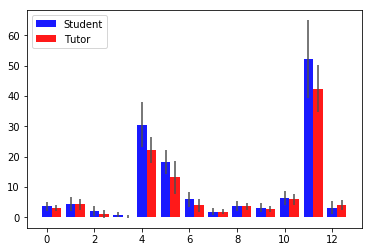

In [115]:
units = np.arange(len(student_rates.T))

rects1 = plt.bar(units, student_rates.mean(axis=0), 0.4,
                 alpha=0.9,
                 color='b',
                 yerr=student_rates.std(axis=0),
                 error_kw={'ecolor': '0.3'},
                 label='Student')

rects2 = plt.bar(units + 0.4, tutor_rates.mean(axis=0), 0.4,
                 alpha=0.9,
                 color='r',
                 yerr=tutor_rates.std(axis=0),
                 error_kw={'ecolor': '0.3'},
                 label='Tutor')

plt.legend(loc="upper left")
plt.show()

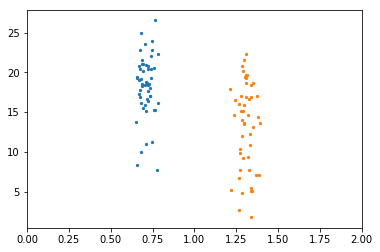

In [134]:
x = lambda n: np.random.normal(0, 0.04, size=n)
plt.scatter(x(len(student_rates)) + 0.7, student_rates[:, 5], s=5)
plt.scatter(x(len(tutor_rates)) + 1.3, tutor_rates[:, 5], s=5)
plt.xlim(0, 2)
plt.show()

# ISI

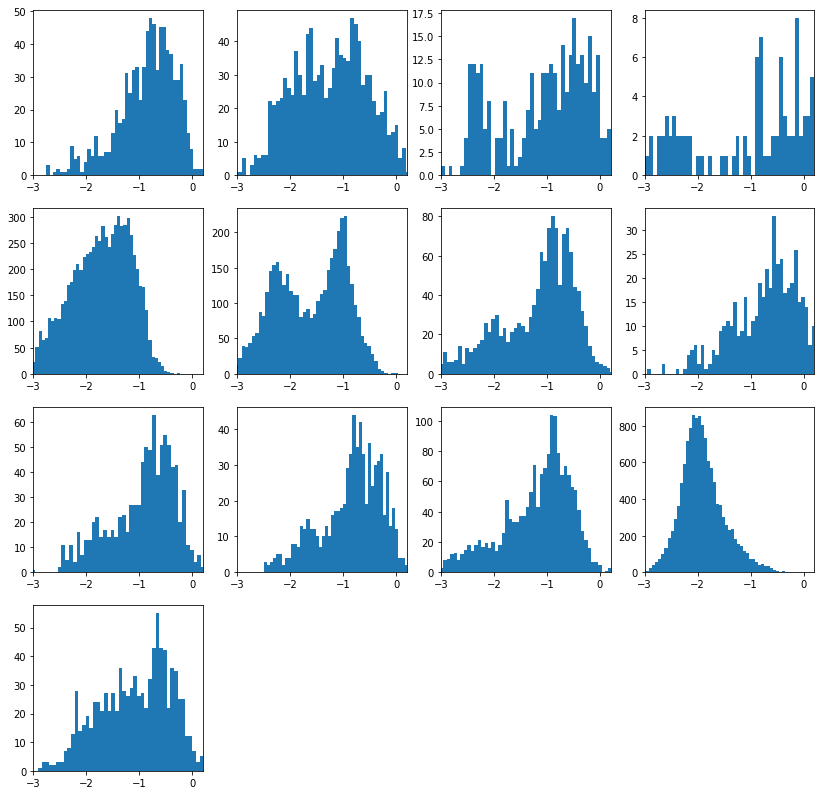

In [271]:
plt.figure(figsize=(14, 14))

for i in range(13):
    isis = []
    plt.subplot(4, 4, i+1)
    for seg in block.segments:
        st = seg.spiketrains[i]
        isis += list(st.times.as_array()[1:] - st.times.as_array()[:-1])
    plt.hist(np.log10(isis), bins=50)
    plt.xlim(-3, 0.2)
plt.show()